In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import matplotlib.colors as colors
from matplotlib.lines import Line2D
import pandas as pd
from scipy.stats.mstats import gmean
import os as os
import glob
import sys
import re
import argparse
import gzip
from contextlib import contextmanager
from scipy import optimize


sys.path.insert(0, "src")

import atmosphere
import cts
import olr
import optical
import lbl_read
import parameters
from constants import ps, g, nu_rot, nu_vr, nu_co2, nu_min, nu_max

In [2]:
import matplotlib as mpl
with plt.style.context('tableau-colorblind10'):
    cb_colors = mpl.rcParams['axes.prop_cycle'].by_key()['color']

# Line by line data and idealized model construction

## H2O

In [3]:
# Assume that the line-by-line data are in a folder named lbl_data
# nu, tau, trans, pres = read_tau("lbl_data/dto1_4asub1fmt_idealized_atmosphere--10-2500-ZH-0.-1.-0.-0.-0.-CNO-A0.-Iinf-PTOA-UPExphr20_RF5E-4nu.plt")
nu, tau, trans, pres = lbl_read.read_tau("../lbl_data/dto1_4asub1fmt_idealized_atmosphere--10-2500-ZH-0.-1.-0.-0.-0.-CNO-A0.-Iinf-PTOA-UPExphr20_RF5E-4.plt")

In [4]:
tau = np.cumsum(tau, axis=0)
trans = np.exp(-tau)

In [5]:
# Assume that the line-by-line data are in a folder named lbl_data

T, T_half, q, q_half, p, p_half = lbl_read.atmosphere_4a()

In [6]:
n_height = tau.shape[0]

In [7]:
tau_mean_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_mean_h2o[:,k-23] = np.mean(tau_interval, axis=1)
tau_mean_h2o = np.concatenate((np.zeros_like(tau_mean_h2o[0]).reshape(1,-1), tau_mean_h2o))

In [8]:
tau_median_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_median_h2o[:,k-23] = np.median(tau_interval, axis=1)
tau_median_h2o = np.concatenate((np.zeros_like(tau_median_h2o[0]).reshape(1,-1), tau_median_h2o))

In [9]:
tau_geom_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_geom_h2o[:,k-23] = gmean(tau_interval, axis=1)
tau_geom_h2o = np.concatenate((np.zeros_like(tau_geom_h2o[0]).reshape(1,-1), tau_geom_h2o))

In [10]:
trans_ref_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    trans_interval = trans[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    trans_ref_h2o[:,k-23] = np.mean(trans_interval, axis=1)
trans_ref_h2o = np.concatenate((np.ones_like(trans_ref_h2o[0]).reshape(1,-1), trans_ref_h2o))

In [11]:
nu_smooth = np.arange(23, 2487)

In [12]:
trans_mean_h2o = np.exp(-tau_mean_h2o)
trans_median_h2o = np.exp(-tau_median_h2o)
trans_geom_h2o = np.exp(-tau_geom_h2o)

gamma_s = 0.1
trans_avg_malkmus_h2o = optical.trans_malkmus(tau_mean_h2o, gamma_s*p_half/p_half[-1])

In [13]:
k_median_h2o = (tau_median_h2o[1:] - tau_median_h2o[:-1]) / ((p_half[1:] - p_half[:-1]) *  q).reshape(-1,1) * g

In [14]:

nu_left_bound = 50
nu_right_bound = 1600
p_ref_i = 50

def k_param_h2o(nu, k_rot, lrot, k_vr, lvr):
    return np.max((k_rot * np.exp(-np.abs(nu-nu_rot)/lrot), k_vr * np.exp(-np.abs(nu-nu_vr)/lvr)),axis=0)

def logk_param_h2o(nu, logk_rot, lrot, logk_vr, lvr):
    return np.max((logk_rot - np.abs(nu - nu_rot)/lrot, logk_vr - np.abs(nu - nu_vr)/lvr),axis=0)

logparam_h2o, _, info, msg, ier = optimize.curve_fit(logk_param_h2o, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_h2o[p_ref_i])[nu_left_bound:nu_right_bound], p0 = [np.log(165), 5500, np.log(15), 3800], full_output=True, method='lm')


parameters.kappa_rot = np.exp(logparam_h2o[0]) * (ps/p[p_ref_i])
parameters.l_rot = logparam_h2o[1] 
parameters.kappa_vr = np.exp(logparam_h2o[2]) * (ps/p[p_ref_i])
parameters.l_vr = logparam_h2o[3]
parameters.nu_mid = (np.log(parameters.kappa_rot/parameters.kappa_vr) + nu_vr/parameters.l_vr + nu_rot/parameters.l_rot)/(1/parameters.l_vr + 1/parameters.l_rot)

print(f"kappa_rot = {parameters.kappa_rot}")
print(f"kappa_vr = {parameters.kappa_vr}")
print(f"l_vr = {parameters.l_vr/100}")
print(f"nu_mid = {parameters.nu_mid/100}")


kappa_rot = 209.72212502047404
kappa_vr = 31.142757464873892
l_vr = 37.05479711948108
nu_mid = 1008.493350402691


In [15]:
l_rot_p = np.zeros(tau.shape[0]-1)
kappa_rot_p = np.zeros(tau.shape[0]-1)
l_vr_p = np.zeros(tau.shape[0]-1)
kappa_vr_p = np.zeros(tau.shape[0]-1)

nu_left_bound = 50
nu_right_bound = 1600

for p_ref_i in range(tau.shape[0]-1):
    mask = (k_median_h2o[p_ref_i] > 1e-30)
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_h2o, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_h2o[p_ref_i])[nu_left_bound:nu_right_bound], p0 = [np.log(165), 5500, np.log(15), 3800], full_output=True, method='lm')
    kappa_rot_p[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_rot_p[p_ref_i] = logparam[1]/100 
    kappa_vr_p[p_ref_i]= np.exp(logparam[2])#* p[50] / p[p_ref_i]
    l_vr_p[p_ref_i] = logparam[3]/100 
    

In [16]:
k_idealized = k_param_h2o(nu_smooth.reshape(1,-1)*100, kappa_rot_p.reshape(-1,1), l_rot_p.reshape(-1,1)*100, kappa_vr_p.reshape(-1,1), l_vr_p.reshape(-1,1)*100)
k_idealized = np.concatenate((np.zeros_like(k_idealized[0].reshape(1,-1)),k_idealized))
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = q[-1] + np.zeros(k_idealized.shape[0])

tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_p_h2o = np.exp(-tau_idealized)


In [17]:
p_ref_i = 50
k_idealized = k_param_h2o(nu_smooth*100, kappa_rot_p[p_ref_i], l_rot_p[p_ref_i]*100, kappa_vr_p[p_ref_i], l_vr_p[p_ref_i]*100)
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = (p_half[:-1]*q_half[:-1] + p_half[1:]*q_half[1:])/2 
Q_p = np.cumsum(delta_p * trapeizodal_pq, axis = 0) / (p[p_ref_i]  * g)

tau_idealized = Q_p.reshape(-1,1) *k_idealized.reshape(1,-1)
trans_idealized_h2o = np.exp(-tau_idealized)


In [18]:
p_ref_i = 50
k_idealized = k_param_h2o(nu_smooth*100, (p.reshape(-1,1)/p[p_ref_i])*kappa_rot_p[p_ref_i], l_rot_p[p_ref_i]*100* np.sqrt(T.reshape(-1,1)/T[p_ref_i]), (p.reshape(-1,1)/p[p_ref_i])**(1)*kappa_vr_p[p_ref_i], l_vr_p[p_ref_i]*100* np.sqrt(T.reshape(-1,1)/T[p_ref_i]))
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = (q_half[:-1] + q_half[1:])/2 
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_fit_h2o = np.exp(-tau_idealized)


## CO2

In [19]:
# Assume that the line-by-line data are in a folder named lbl_data

nu, tau, trans, pres = lbl_read.read_tau("../lbl_data/dto1_4asub1fmt_idealized_atmosphere--10-2500-ZH-395.-0.-0.-0.-0.-CNO-A0.-Iinf-PTOA-UPExphr20_RF5E-4.plt")

In [20]:
tau = np.cumsum(tau, axis=0)
trans = np.exp(-tau)

In [21]:
# Assume that the line-by-line data are in a folder named lbl_data

T, T_half, q, q_half, p, p_half = lbl_read.atmosphere_4a()
qco2 = 400e-6

In [22]:
n_height = tau.shape[0]

In [23]:
tau_mean_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_mean_co2[:,k-23] = np.mean(tau_interval, axis=1)
tau_mean_co2 = np.concatenate((np.zeros_like(tau_mean_co2[0]).reshape(1,-1), tau_mean_co2))

In [24]:
tau_median_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_median_co2[:,k-23] = np.median(tau_interval, axis=1)
tau_median_co2 = np.concatenate((np.zeros_like(tau_median_co2[0]).reshape(1,-1), tau_median_co2))

In [25]:
tau_geom_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_geom_co2[:,k-23] = gmean(tau_interval, axis=1)
tau_geom_co2 = np.concatenate((np.zeros_like(tau_geom_co2[0]).reshape(1,-1), tau_geom_co2))

In [26]:
trans_ref_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    trans_interval = trans[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    trans_ref_co2[:,k-23] = np.mean(trans_interval, axis=1)
trans_ref_co2 = np.concatenate((np.ones_like(trans_ref_co2[0]).reshape(1,-1), trans_ref_co2))

In [27]:
nu_smooth = np.arange(23, 2487)

In [28]:
trans_mean_co2 = np.exp(-tau_mean_co2)
trans_median_co2 = np.exp(-tau_median_co2)
trans_geom_co2 = np.exp(-tau_geom_co2)
gamma_s = 0.1
trans_avg_malkmus_co2 = optical.trans_malkmus(tau_mean_co2, gamma_s*p_half/ps)

In [29]:
delta_p = (p_half[1:] - p_half[:-1])
k_median_co2 = (tau_median_co2[1:] - tau_median_co2[:-1]) / (delta_p *  qco2).reshape(-1,1) * g

In [30]:
p_ref_i = 50

nu_left_bound = 667 - 100
nu_right_bound = 667 + 100

def k_param_co2(nu, k_co2, l_co2):
    return k_co2 * np.exp(-np.abs(nu-nu_co2)/l_co2)

def logk_param_co2(nu, logk_co2, l_co2):
    return logk_co2 - np.abs(nu - nu_co2)/l_co2


mask = (k_median_co2[p_ref_i] > 1e-30)
logparam_co2, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500 * p[p_ref_i]/ps), 1020], full_output=True, method='lm')

parameters.kappa_co2 = np.exp(logparam_co2[0]) * ps/p[p_ref_i]
parameters.l_co2 = logparam_co2[1]
print(f"kappa_co2 = {parameters.kappa_co2}")
print(f"l_co2 = {parameters.l_co2/100}")

kappa_co2 = 297.6318651032787
l_co2 = 11.635298354329143


In [31]:
nu_left_bound = 667 - 50
nu_right_bound = 667 + 50
l_co2_p = np.zeros(tau.shape[0]-1)
kappa_co2_p = np.zeros(tau.shape[0]-1)
for p_ref_i in range(tau.shape[0]-1):
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500), 1020], full_output=True, method='lm')    
    kappa_co2_p[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_co2_p[p_ref_i] = logparam[1]/100 

In [32]:
nu_left_bound = 667 - 100
nu_right_bound = 667 + 100
l_co2_p_pm100 = np.zeros(tau.shape[0]-1)
kappa_co2_p_pm100 = np.zeros(tau.shape[0]-1)
for p_ref_i in range(tau.shape[0]-1):
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500), 1020], full_output=True, method='lm')    
    kappa_co2_p_pm100[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_co2_p_pm100[p_ref_i] = logparam[1]/100 

In [33]:
nu_left_bound = 667 - 150
nu_right_bound = 667 + 150
l_co2_p_pm150 = np.zeros(tau.shape[0]-1)
kappa_co2_p_pm150 = np.zeros(tau.shape[0]-1)
for p_ref_i in range(tau.shape[0]-1):
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500), 1020], full_output=True, method='lm')    
    kappa_co2_p_pm150[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_co2_p_pm150[p_ref_i] = logparam[1]/100 

In [34]:
k_idealized = k_param_co2(nu_smooth.reshape(1,-1)*100, kappa_co2_p.reshape(-1,1), l_co2_p.reshape(-1,1)*100)
k_idealized = np.concatenate((np.zeros_like(k_idealized[0].reshape(1,-1)),k_idealized))

delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = qco2 + np.zeros(k_idealized.shape[0])
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_p_co2 = np.exp(-tau_idealized)

In [35]:
p_ref_i = 50
k_idealized = k_param_co2(nu_smooth*100, kappa_co2_p[p_ref_i], l_co2_p[p_ref_i]*100)
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = (p_half[:-1] + p_half[1:])/2 * qco2
Q_p = np.cumsum(delta_p * trapeizodal_pq, axis = 0) / (p[p_ref_i]  * g)

tau_idealized = Q_p.reshape(-1,1) *k_idealized.reshape(1,-1)
trans_idealized_co2 = np.exp(-tau_idealized)


In [36]:
p_ref_i = 50
k_idealized = k_param_co2(nu_smooth*100, kappa_co2_p[p_ref_i] * np.sqrt(p[p_ref_i]/p.reshape(-1,1))**(-1), l_co2_p[p_ref_i]*100 * T.reshape(-1,1)/T[p_ref_i])
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = qco2 + np.zeros(k_idealized.shape[0])
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_fit_co2 = np.exp(-tau_idealized)


In [37]:
p_ref_i = 50
k_idealized = k_param_co2(nu_smooth*100, kappa_co2_p[p_ref_i] * np.sqrt(p[p_ref_i]/p.reshape(-1,1))**(-1), l_co2_p[p_ref_i]*100 )
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = qco2 + np.zeros(k_idealized.shape[0])
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_fit_onlykappa_co2 = np.exp(-tau_idealized)


# Figures for smoothing and pressure scaling

In [38]:
color_mean_trans =  cb_colors[3]
color_mean_optical = cb_colors[0]
color_median_optical = cb_colors[1]
color_malkmus = cb_colors[4]
color_geom_optical = cb_colors[2]

In [39]:
p_tp = atmosphere.tropopause(Ts = 300)


## CTS

Text(0.5, 1.0, '(b) $CO_2$: cooling to space')

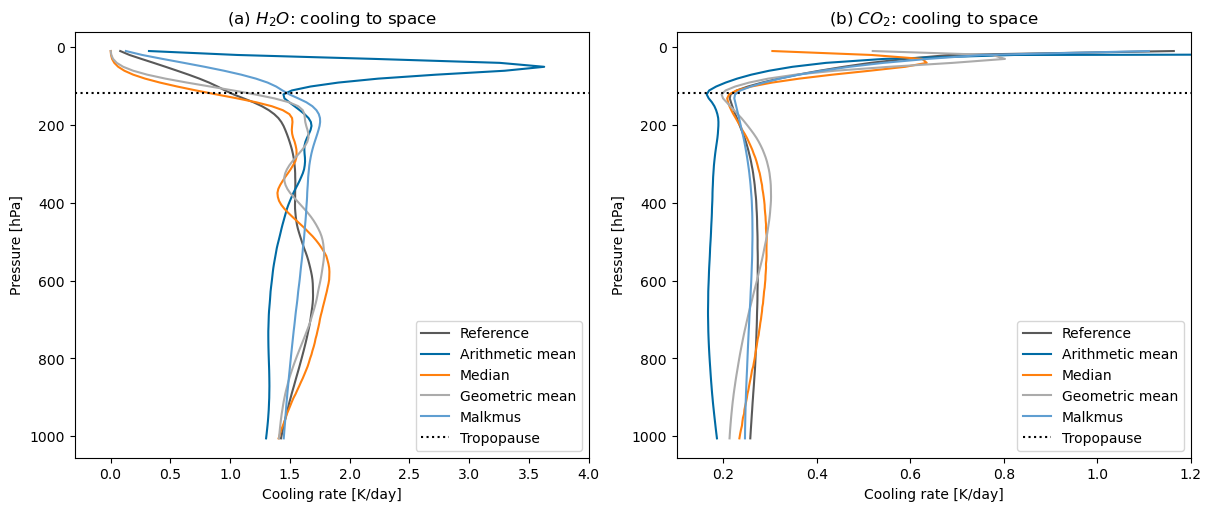

In [40]:
fig, ax = plt.subplots(1,2, squeeze=False, figsize=(12,5), constrained_layout = True)

T, T_half, q, q_half, p, p_half = lbl_read.atmosphere_4a()

nu_left_bound_i = 0
p_lower_bound_i = -2
p_upper_bound_i = 1
dp = p[51] - p[50]
ax[0,0].plot(cts.cts_trans(p_half, q_half, T, trans_ref_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,0].plot(cts.cts_trans(p_half, q_half, T, trans_mean_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Arithmetic mean", color = color_mean_optical)
ax[0,0].plot(cts.cts_trans(p_half, q_half, T, trans_median_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Median", color = color_median_optical)
ax[0,0].plot(cts.cts_trans(p_half, q_half, T, trans_geom_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Geometric mean", color = color_geom_optical)
ax[0,0].plot(cts.cts_trans(p_half, q_half, T, trans_avg_malkmus_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Malkmus", color = color_malkmus)


ax[0,0].hlines(p_tp/100, -0.3,4, color = 'black', linestyle = ':', label = 'Tropopause')

ax[0,0].set_ylabel('Pressure [hPa]')
ax[0,0].set_xlabel('Cooling rate [K/day]')
ax[0,0].set_xlim([-0.3, 4.0])
ax[0,0].legend(loc='lower right')
ax[0,0].invert_yaxis()
ax[0,0].set_title(r"(a) $H_2O$: cooling to space")

ax[0,1].plot(cts.cts_trans(p_half, q_half, T, trans_ref_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,1].plot(cts.cts_trans(p_half, q_half, T, trans_mean_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Arithmetic mean", color = color_mean_optical)
ax[0,1].plot(cts.cts_trans(p_half, q_half, T, trans_median_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Median", color = color_median_optical)
ax[0,1].plot(cts.cts_trans(p_half, q_half, T, trans_geom_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Geometric mean", color = color_geom_optical)
ax[0,1].plot(cts.cts_trans(p_half, q_half, T, trans_avg_malkmus_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Malkmus", color = color_malkmus)

ax[0,1].hlines(p_tp/100, 0.1,1.2, color = 'black', linestyle = ':', label = 'Tropopause')

ax[0,1].set_xlim([0.1,1.2])

ax[0,1].set_ylabel('Pressure [hPa]')
ax[0,1].set_xlabel('Cooling rate [K/day]')
ax[0,1].legend(loc='lower right')
ax[0,1].invert_yaxis()
ax[0,1].set_title(r"(b) $CO_2$: cooling to space")

# plt.savefig("cts_median_h2oco2.pdf")

## OLR

(-0.00023915732800763019, 0.005026125117119864)

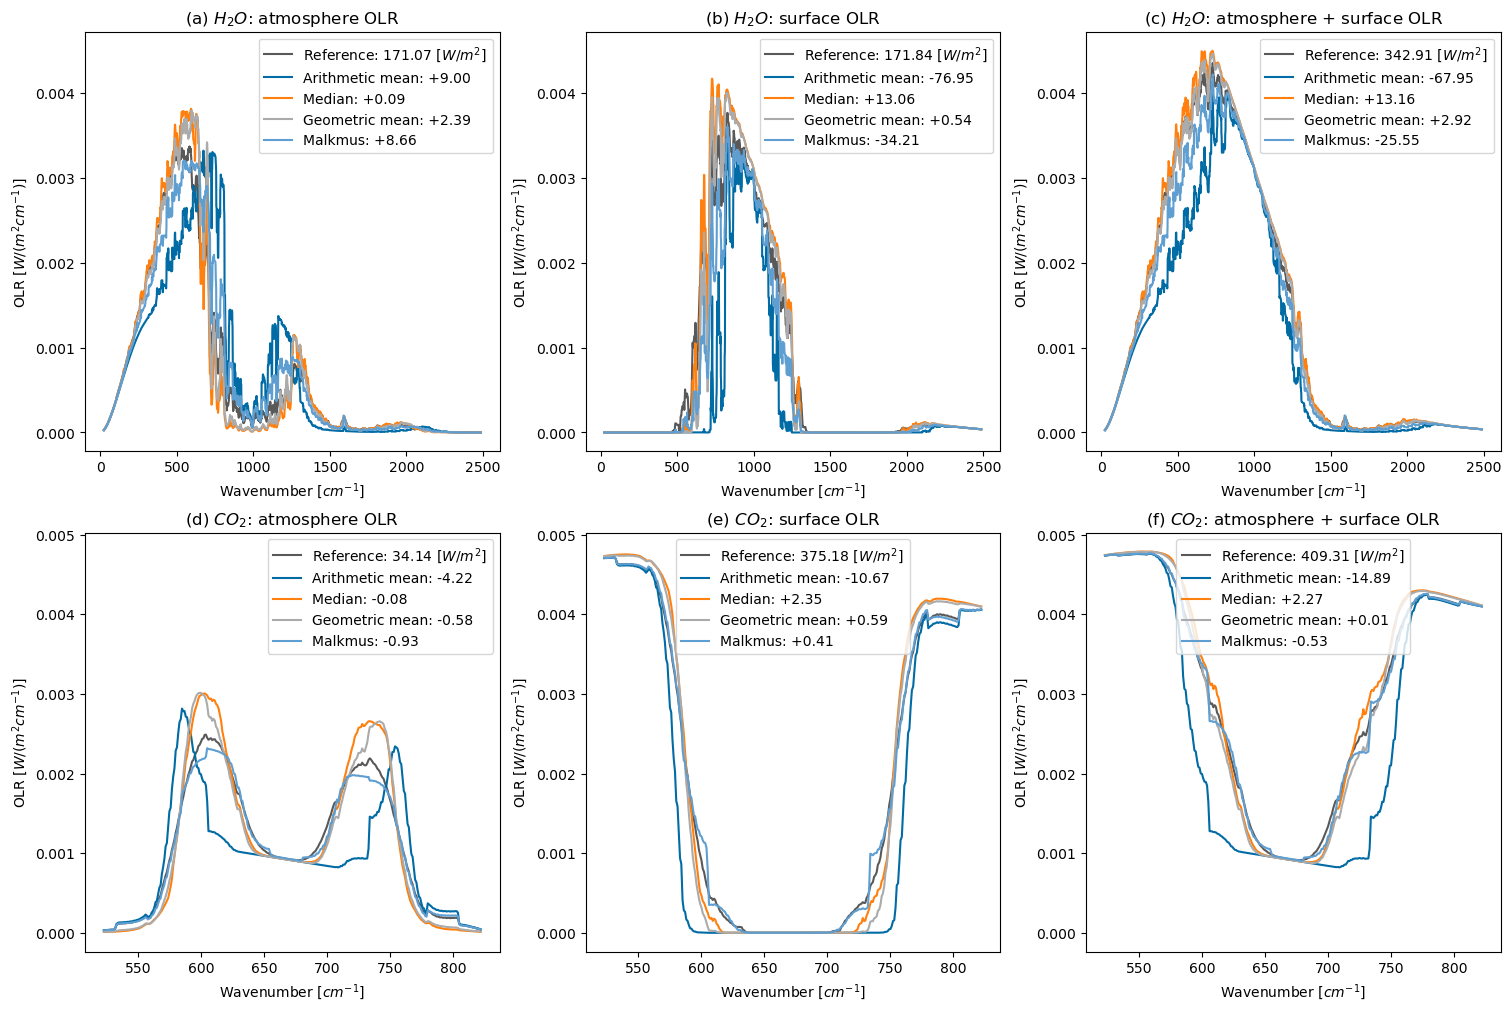

In [41]:
fig, ax = plt.subplots(2,3, squeeze=False, figsize=(15,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = lbl_read.atmosphere_4a()
qco2 = 400e-6
# T, T_half, q, q_half, p, p_half  = T[2:], T_half[2:], q[2:], q_half[2:], p[2:], p_half[2:]


olr_atm, olr_surf = olr.olr_trans(p_half, q_half, T, T_half, trans_ref_h2o, nu_smooth*100)
olr_atm_avg, olr_surf_avg = olr.olr_trans(p_half, q_half, T, T_half, trans_mean_h2o, nu_smooth*100)
olr_atm_median, olr_surf_median = olr.olr_trans(p_half, q_half, T, T_half, trans_median_h2o, nu_smooth*100)
olr_atm_geom, olr_surf_geom = olr.olr_trans(p_half, q_half, T, T_half, trans_geom_h2o, nu_smooth*100)
olr_atm_malkmus, olr_surf_malkmus = olr.olr_trans(p_half, q_half, T, T_half, trans_avg_malkmus_h2o, nu_smooth*100)

delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

olr_atm_tot = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu_smooth)
olr_surf_tot = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu_smooth)
olr_atm_avg_tot = np.sum((olr_atm_avg[1:] + olr_atm_avg[:-1])/2 * delta_nu_smooth)
olr_surf_avg_tot = np.sum((olr_surf_avg[1:] + olr_surf_avg[:-1])/2 * delta_nu_smooth)
olr_atm_median_tot = np.sum((olr_atm_median[1:] + olr_atm_median[:-1])/2 * delta_nu_smooth)
olr_surf_median_tot = np.sum((olr_surf_median[1:] + olr_surf_median[:-1])/2 * delta_nu_smooth)
olr_atm_geom_tot = np.sum((olr_atm_geom[1:] + olr_atm_geom[:-1])/2 * delta_nu_smooth)
olr_surf_geom_tot = np.sum((olr_surf_geom[1:] + olr_surf_geom[:-1])/2 * delta_nu_smooth)
olr_atm_malkmus_tot = np.sum((olr_atm_malkmus[1:] + olr_atm_malkmus[:-1])/2 * delta_nu_smooth)
olr_surf_malkmus_tot = np.sum((olr_surf_malkmus[1:] + olr_surf_malkmus[:-1])/2 * delta_nu_smooth)

y_lim_max = np.max((np.max(olr_atm + olr_surf), np.max((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_min = np.min((np.min(olr_atm + olr_surf), np.min((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[0,0].plot(nu_smooth, olr_atm, label = "Reference", color = color_mean_trans)
ax[0,0].plot(nu_smooth, olr_atm_avg, label = "Mean", color = color_mean_optical)
ax[0,0].plot(nu_smooth, olr_atm_median, label = "Median", color = color_median_optical)
ax[0,0].plot(nu_smooth, olr_atm_geom, label = "Median", color = color_geom_optical)
ax[0,0].plot(nu_smooth, olr_atm_malkmus, label = "Malkmus", color = color_malkmus)

ax[0,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,0].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[0,0].legend([rf"Reference: {olr_atm_tot:.2f} [$W/m^2$]",
                rf"Arithmetic mean: {olr_atm_avg_tot - olr_atm_tot:+.2f}",
                rf"Median: {olr_atm_median_tot - olr_atm_tot:+.2f}",
                rf"Geometric mean: {olr_atm_geom_tot - olr_atm_tot:+.2f}",
                rf"Malkmus: {olr_atm_malkmus_tot - olr_atm_tot:+.2f}"
               ],loc='upper right')
ax[0,0].set_title(r"(a) $H_2O$: atmosphere OLR")
ax[0,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,1].plot(nu_smooth, olr_surf, label = "Reference", color = color_mean_trans)
ax[0,1].plot(nu_smooth, olr_surf_avg, label = "Mean", color = color_mean_optical)
ax[0,1].plot(nu_smooth, olr_surf_median, label = "Median", color = color_median_optical)
ax[0,1].plot(nu_smooth, olr_surf_geom, label = "Median", color = color_geom_optical)
ax[0,1].plot(nu_smooth, olr_surf_malkmus, label = "Malkmus", color = color_malkmus)

ax[0,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,1].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[0,1].legend([rf"Reference: {olr_surf_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {olr_surf_avg_tot - olr_surf_tot:+.2f}", 
                rf"Median: {olr_surf_median_tot - olr_surf_tot:+.2f}",
                rf"Geometric mean: {olr_surf_geom_tot - olr_surf_tot:+.2f}",
                rf"Malkmus: {olr_surf_malkmus_tot - olr_surf_tot:+.2f}"
               ],loc='upper right')
ax[0,1].set_title(r"(b) $H_2O$: surface OLR")
ax[0,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,2].plot(nu_smooth, olr_surf + olr_atm, label = "Reference", color = color_mean_trans)
ax[0,2].plot(nu_smooth, olr_surf_avg + olr_atm_avg, label = "Mean", color = color_mean_optical)
ax[0,2].plot(nu_smooth, olr_surf_median + olr_atm_median, label = "Median", color = color_median_optical)
ax[0,2].plot(nu_smooth, olr_surf_geom + olr_atm_geom, label = "Median", color = color_geom_optical)
ax[0,2].plot(nu_smooth, olr_surf_malkmus + olr_atm_malkmus, label = "Malkmus", color = color_malkmus)

ax[0,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,2].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[0,2].set_title(r"(c) $H_2O$: atmosphere + surface OLR")
ax[0,2].legend([rf"Reference: {olr_surf_tot+olr_atm_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {(olr_surf_avg_tot+olr_atm_avg_tot) - (olr_surf_tot+olr_atm_tot):+.2f}", 
                rf"Median: {(olr_surf_median_tot+olr_atm_median_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Geometric mean: {(olr_surf_geom_tot+olr_atm_geom_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Malkmus: {(olr_surf_malkmus_tot+olr_atm_malkmus_tot) - (olr_surf_tot+olr_atm_tot):+.2f}"
               ],loc='upper right')
ax[0,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)


nu_a = 500
nu_b = 800

olr_atm, olr_surf = olr.olr_trans(p_half, q_half, T, T_half, trans_ref_co2, nu_smooth*100)
olr_atm_avg, olr_surf_avg = olr.olr_trans(p_half, q_half, T, T_half, trans_mean_co2, nu_smooth*100)
olr_atm_median, olr_surf_median = olr.olr_trans(p_half, q_half, T, T_half, trans_median_co2, nu_smooth*100)
olr_atm_geom, olr_surf_geom = olr.olr_trans(p_half, q_half, T, T_half, trans_geom_co2, nu_smooth*100)
olr_atm_malkmus, olr_surf_malkmus = olr.olr_trans(p_half, q_half, T, T_half, trans_avg_malkmus_co2, nu_smooth*100)

delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

olr_atm_tot = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu_smooth)
olr_surf_tot = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu_smooth)
olr_atm_avg_tot = np.sum((olr_atm_avg[1:] + olr_atm_avg[:-1])/2 * delta_nu_smooth)
olr_surf_avg_tot = np.sum((olr_surf_avg[1:] + olr_surf_avg[:-1])/2 * delta_nu_smooth)
olr_atm_median_tot = np.sum((olr_atm_median[1:] + olr_atm_median[:-1])/2 * delta_nu_smooth)
olr_surf_median_tot = np.sum((olr_surf_median[1:] + olr_surf_median[:-1])/2 * delta_nu_smooth)
olr_atm_geom_tot = np.sum((olr_atm_geom[1:] + olr_atm_geom[:-1])/2 * delta_nu_smooth)
olr_surf_geom_tot = np.sum((olr_surf_geom[1:] + olr_surf_geom[:-1])/2 * delta_nu_smooth)
olr_atm_malkmus_tot = np.sum((olr_atm_malkmus[1:] + olr_atm_malkmus[:-1])/2 * delta_nu_smooth)
olr_surf_malkmus_tot = np.sum((olr_surf_malkmus[1:] + olr_surf_malkmus[:-1])/2 * delta_nu_smooth)


y_lim_max = np.max((np.max(olr_atm + olr_surf), np.max((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_min = np.min((np.min(olr_atm + olr_surf), np.min((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm[nu_a:nu_b], label = "Reference", color = color_mean_trans)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_avg[nu_a:nu_b], label = "Mean", color = color_mean_optical)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_median[nu_a:nu_b], label = "Median", color = color_median_optical)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_geom[nu_a:nu_b], label = "Median", color = color_geom_optical)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_malkmus[nu_a:nu_b], label = "Malkmus", color = color_malkmus)

ax[1,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,0].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[1,0].legend([rf"Reference: {olr_atm_tot:.2f} [$W/m^2$]",
                rf"Arithmetic mean: {olr_atm_avg_tot - olr_atm_tot:+.2f}",
                rf"Median: {olr_atm_median_tot - olr_atm_tot:+.2f}",
                rf"Geometric mean: {olr_atm_geom_tot - olr_atm_tot:+.2f}",
                rf"Malkmus: {olr_atm_malkmus_tot - olr_atm_tot:+.2f}"
               ],loc='upper right')
ax[1,0].set_title(r"(d) $CO_2$: atmosphere OLR")
ax[1,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf[nu_a:nu_b], label = "Reference", color = color_mean_trans)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_avg[nu_a:nu_b], label = "Mean", color = color_mean_optical)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_median[nu_a:nu_b], label = "Median", color = color_median_optical)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_geom[nu_a:nu_b], label = "Median", color = color_geom_optical)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_malkmus[nu_a:nu_b], label = "Malkmus", color = color_malkmus)

ax[1,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,1].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[1,1].legend([rf"Reference: {olr_surf_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {olr_surf_avg_tot - olr_surf_tot:+.2f}", 
                rf"Median: {olr_surf_median_tot - olr_surf_tot:+.2f}",
                rf"Geometric mean: {olr_surf_geom_tot - olr_surf_tot:+.2f}",
                rf"Malkmus: {olr_surf_malkmus_tot - olr_surf_tot:+.2f}"
               ],loc='upper center')
ax[1,1].set_title(r"(e) $CO_2$: surface OLR")
ax[1,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf[nu_a:nu_b] + olr_atm[nu_a:nu_b], label = "Reference", color = color_mean_trans)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_avg[nu_a:nu_b] + olr_atm_avg[nu_a:nu_b], label = "Mean", color = color_mean_optical)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_median[nu_a:nu_b] + olr_atm_median[nu_a:nu_b], label = "Median", color = color_median_optical)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_geom[nu_a:nu_b] + olr_atm_geom[nu_a:nu_b], label = "Median", color = color_geom_optical)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_malkmus[nu_a:nu_b] + olr_atm_malkmus[nu_a:nu_b], label = "Malkmus", color = color_malkmus)

ax[1,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,2].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[1,2].set_title(r"(f) $CO_2$: atmosphere + surface OLR")


ax[1,2].legend([rf"Reference: {olr_surf_tot+olr_atm_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {(olr_surf_avg_tot+olr_atm_avg_tot) - (olr_surf_tot+olr_atm_tot):+.2f}", 
                rf"Median: {(olr_surf_median_tot+olr_atm_median_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Geometric mean: {(olr_surf_geom_tot+olr_atm_geom_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Malkmus: {(olr_surf_malkmus_tot+olr_atm_malkmus_tot) - (olr_surf_tot+olr_atm_tot):+.2f}"
               ],loc='upper center')
ax[1,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

# plt.savefig("OLR_median_h2oco2.pdf")

## Parameters of idealized model at each pressure level

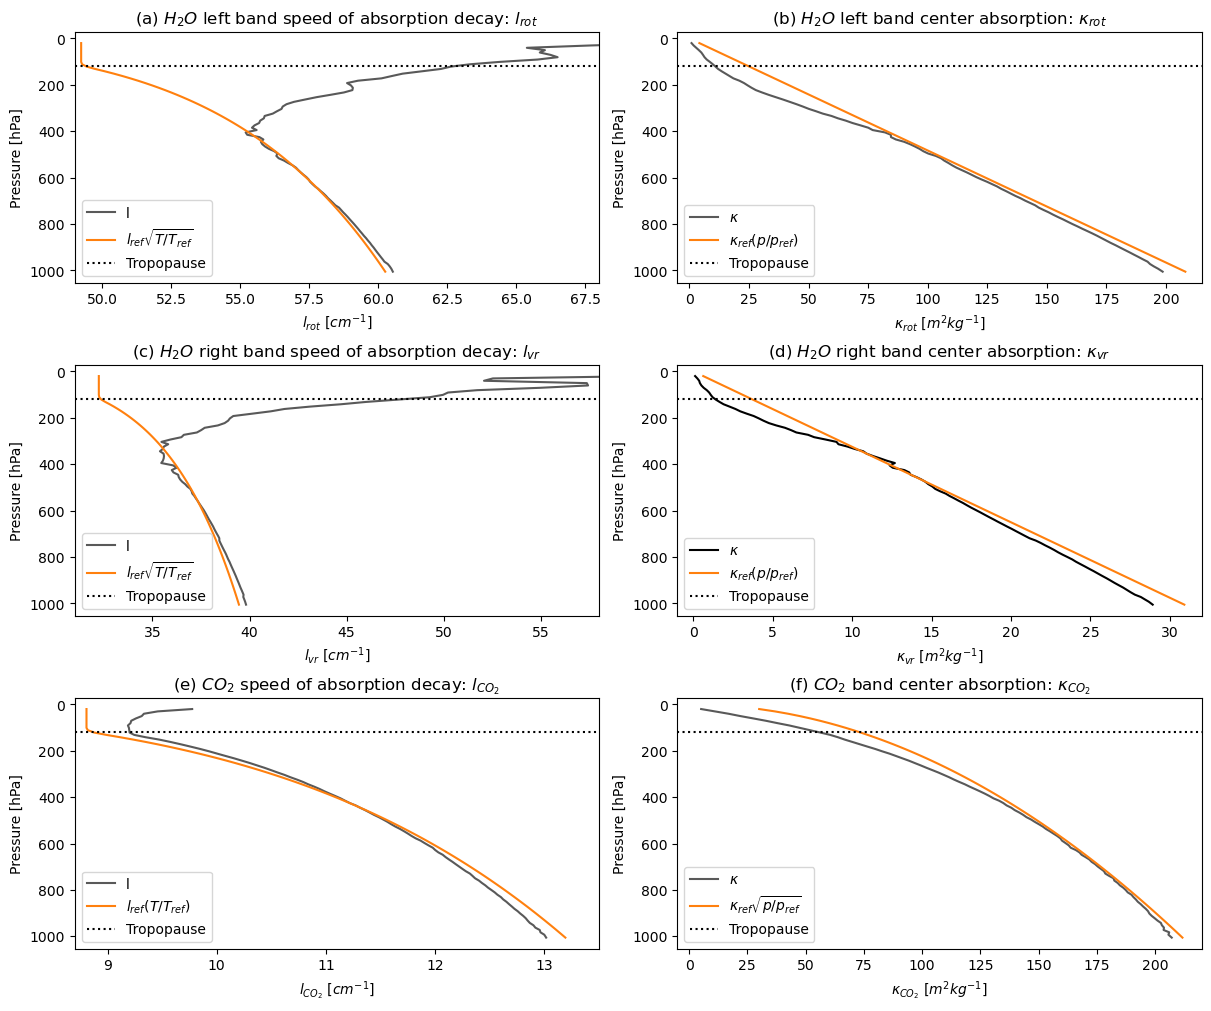

In [42]:
fig, ax = plt.subplots(3,2, squeeze=False, figsize=(12,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = lbl_read.atmosphere_4a()


ax[0,0].plot(l_rot_p, p[1:]/100, color = cb_colors[3], label = "l")
ax[0,0].plot(l_rot_p[50] * (np.sqrt(T[1:]/T[50])), p[1:]/100, color = cb_colors[1], label = r"$l_{ref} \sqrt{T/T_{ref}}$")
ax[0,0].hlines(p_tp/100, 49,68, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,0].set_xlim([49,68])

ax[0,1].plot(kappa_rot_p, p[1:]/100, color = cb_colors[3], label = r"$\kappa$")
ax[0,1].plot((p[1:]/p[50])*kappa_rot_p[50], p[1:]/100, color = cb_colors[1], label = r"$\kappa_{ref}(p/p_{ref})$")
ax[0,1].hlines(p_tp/100, -5,215, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,1].set_xlim([-5,215])


ax[0,0].set_title(r"(a) $H_2O$ left band speed of absorption decay: $l_{rot}$")
ax[0,0].set_ylabel('Pressure [hPa]')
ax[0,0].set_xlabel(r"$l_{rot}$ [$cm^{-1}$]")
ax[0,0].legend(loc='lower left')
ax[0,0].invert_yaxis()

ax[0,1].set_title(r"(b) $H_2O$ left band center absorption: $\kappa_{rot}$")
ax[0,1].set_ylabel('Pressure [hPa]')
ax[0,1].set_xlabel(r"$\kappa_{rot}$ [$m^2 kg^{-1}$]")
ax[0,1].legend(loc='lower left')
ax[0,1].invert_yaxis()


ax[1,0].plot(l_vr_p, p[1:]/100, color = cb_colors[3], label = "l")
ax[1,0].plot(l_vr_p[50] * np.sqrt(T[1:]/T[50]), p[1:]/100, color = cb_colors[1], label = r"$l_{ref} \sqrt{T/T_{ref}}$")
ax[1,0].hlines(p_tp/100,31,58, color = 'black', linestyle = ':', label = 'Tropopause')
ax[1,0].set_xlim([31,58])

ax[1,1].plot(kappa_vr_p, p[1:]/100, color = 'black', label = r"$\kappa$")
ax[1,1].plot((p[1:]/p[50])*kappa_vr_p[50], p[1:]/100, color = cb_colors[1], label = r"$\kappa_{ref}(p/p_{ref})$")
ax[1,1].hlines(p_tp/100,-1,32, color = 'black', linestyle = ':', label = 'Tropopause')
ax[1,1].set_xlim([-1,32])

ax[1,0].set_title(r"(c) $H_2O$ right band speed of absorption decay: $l_{vr}$")
ax[1,0].set_ylabel('Pressure [hPa]')
ax[1,0].set_xlabel(r"$l_{vr}$ [$cm^{-1}$]")
ax[1,0].legend(loc='lower left')
ax[1,0].invert_yaxis()

ax[1,1].set_title(r"(d) $H_2O$ right band center absorption: $\kappa_{vr}$")
ax[1,1].set_ylabel('Pressure [hPa]')
ax[1,1].set_xlabel(r"$\kappa_{vr}$ [$m^2 kg^{-1}$]")
ax[1,1].legend(loc='lower left')
ax[1,1].invert_yaxis()


ax[2,0].plot(l_co2_p_pm100, p[1:]/100, color = cb_colors[3], label = "l")
ax[2,0].plot(l_co2_p_pm100[50] * (T[1:]/T[50]), p[1:]/100, color = cb_colors[1], label = r"$l_{ref} (T/T_{ref})$")
ax[2,0].hlines(p_tp/100,8.7,13.5, color = 'black', linestyle = ':', label = 'Tropopause')
ax[2,0].set_xlim([8.7,13.5])


ax[2,1].plot(kappa_co2_p_pm100, p[1:]/100, color = cb_colors[3], label = r"$\kappa$")
ax[2,1].plot(np.sqrt(p[1:]/p[50])*kappa_co2_p_pm100[50], p[1:]/100, color = cb_colors[1], label = r"$\kappa_{ref}\sqrt{p/p_{ref}}$")
ax[2,1].hlines(p_tp/100,-5,220, color = 'black', linestyle = ':', label = 'Tropopause')
ax[2,1].set_xlim([-5,220])


ax[2,0].set_title(r"(e) $CO_2$ speed of absorption decay: $l_{CO_2}$")
ax[2,0].set_ylabel('Pressure [hPa]')
ax[2,0].set_xlabel(r"$l_{CO_2}$ [$cm^{-1}$]")
ax[2,0].legend(loc='lower left')
ax[2,0].invert_yaxis()

ax[2,1].set_title(r"(f) $CO_2$ band center absorption: $\kappa_{CO_2}$")
ax[2,1].set_ylabel('Pressure [hPa]')
ax[2,1].set_xlabel(r"$\kappa_{CO_2}$ [$m^2 kg^{-1}$]")
ax[2,1].legend(loc='lower left')
ax[2,1].invert_yaxis()

# plt.savefig("l_kappa_h2oco2.pdf")

## CTS with idealized model

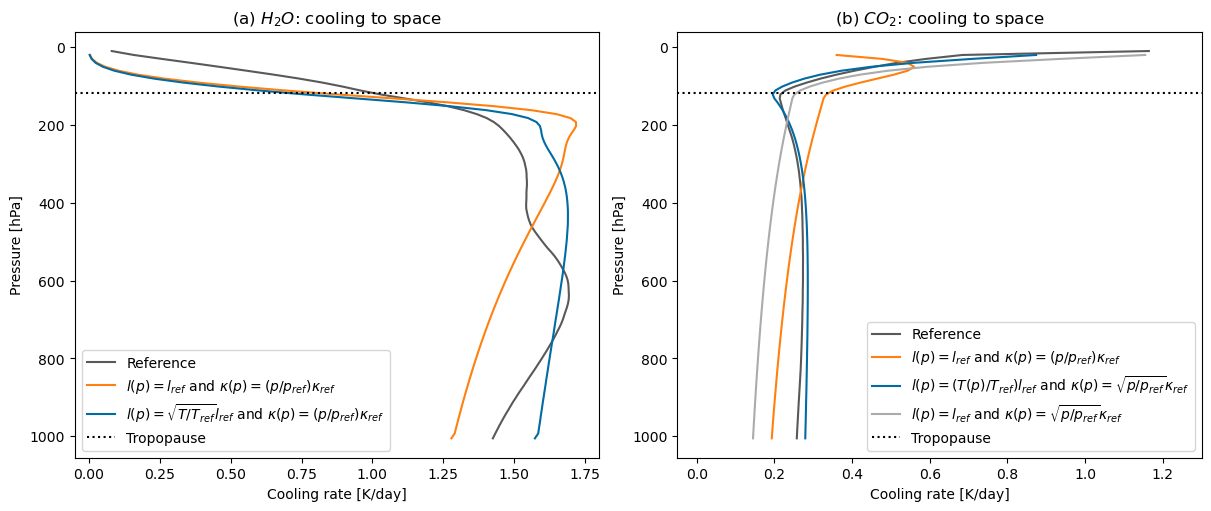

In [43]:
fig, ax = plt.subplots(1,2, squeeze=False, figsize=(12,5), constrained_layout = True)

T, T_half, q, q_half, p, p_half = lbl_read.atmosphere_4a()
qco2 = 400e-6


nu_left_bound_i = 0
p_lower_bound_i = -2
dp = p[51] - p[50]

ax[0,0].plot(cts.cts_trans(p_half, q_half, T, trans_ref_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,0].plot(cts.cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_h2o, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = l_{ref}$ and $\kappa(p) = (p/p_{ref})\kappa_{ref}$", color = cb_colors[1], linestyle = "-")
ax[0,0].plot(cts.cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_fit_h2o, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = \sqrt{T/T_{ref}} l_{ref}$ and $\kappa(p) = (p/p_{ref})\kappa_{ref}$", color = cb_colors[0], linestyle = "-")


# ax[0,0].plot(CTS_lbl_h2o[:-1] * 3600 * 24, p[:-2]/100, label = "Reference", color = 'black')

ax[0,0].hlines(p_tp/100, -0.05, 1.8, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,0].set_xlim([-0.05, 1.8])

ax[0,0].set_ylabel('Pressure [hPa]')
ax[0,0].set_xlabel('Cooling rate [K/day]')
ax[0,0].set_title(r"(a) $H_2 O$: cooling to space")
ax[0,0].legend(loc='lower left')
ax[0,0].invert_yaxis()

nu_left_bound_i = 0
p_lower_bound_i = -2
dp = p[51] - p[50]

ax[0,1].plot(cts.cts_trans(p_half, q_half, T, trans_ref_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,1].plot(cts.cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_co2, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = l_{ref}$ and $\kappa(p) = (p/p_{ref})\kappa_{ref}$", color = cb_colors[1], linestyle = "-")
ax[0,1].plot(cts.cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_fit_co2, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) =(T(p)/T_{ref}) l_{ref}$ and $\kappa(p)=\sqrt{p/p_{ref}}\kappa_{ref}$", color = cb_colors[0], linestyle = "-")
ax[0,1].plot(cts.cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_fit_onlykappa_co2, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = l_{ref}$ and $\kappa(p)=\sqrt{p/p_{ref}}\kappa_{ref}$", color = cb_colors[2], linestyle = "-")

ax[0,1].hlines(p_tp/100, -0.05, 1.3, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,1].set_xlim([-0.05, 1.3])


ax[0,1].set_ylabel('Pressure [hPa]')
ax[0,1].set_xlabel('Cooling rate [K/day]')
ax[0,1].set_title(r"(b) $CO_2$: cooling to space")
ax[0,1].legend(loc='lower right')
ax[0,1].invert_yaxis()
# plt.savefig("cts_idealized_models_h2oco2.pdf")

## OLR with idealized model

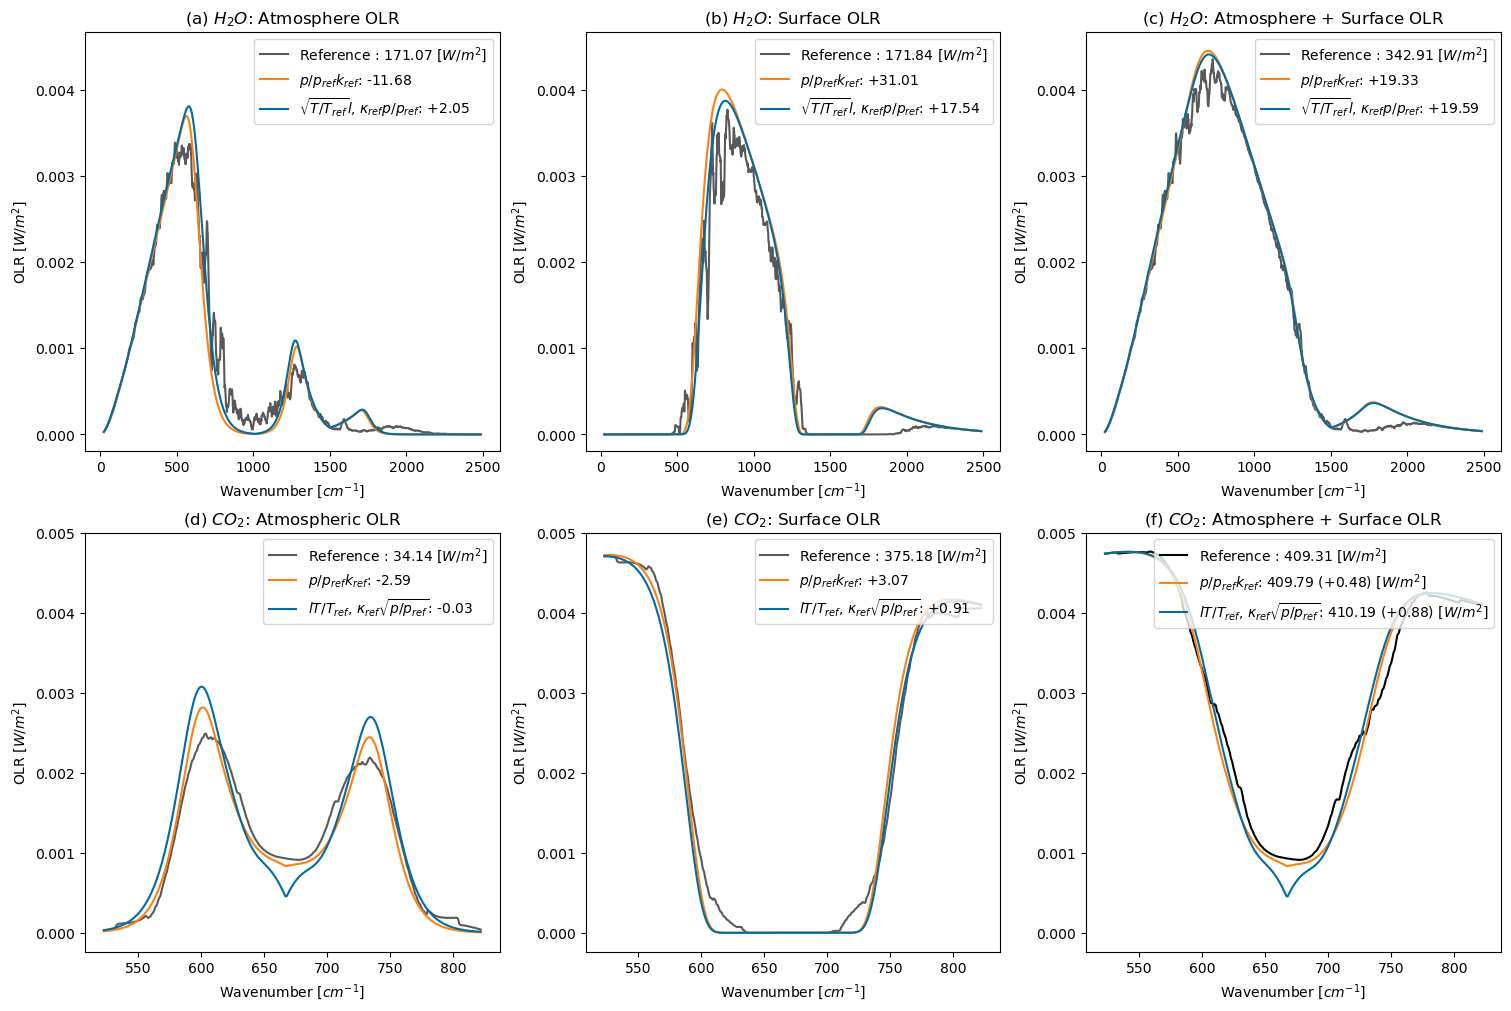

In [44]:
fig, ax = plt.subplots(2,3, squeeze=False, figsize=(15,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = lbl_read.atmosphere_4a()
qco2 = 400e-6


olr_atm, olr_surf = olr.olr_trans(p_half, q_half, T, T_half, trans_ref_h2o, nu_smooth*100)
olr_atm_classic, olr_surf_classic = olr.olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_h2o, nu_smooth*100)
olr_atm_avg_fit, olr_surf_avg_fit = olr.olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_fit_h2o, nu_smooth*100)

delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

olr_atm_tot = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu_smooth)
olr_surf_tot = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu_smooth)
olr_atm_classic_tot = np.sum((olr_atm_classic[1:] + olr_atm_classic[:-1])/2 * delta_nu_smooth)
olr_surf_classic_tot = np.sum((olr_surf_classic[1:] + olr_surf_classic[:-1])/2 * delta_nu_smooth)
olr_atm_avg_fit_tot = np.sum((olr_atm_avg_fit[1:] + olr_atm_avg_fit[:-1])/2 * delta_nu_smooth)
olr_surf_avg_fit_tot = np.sum((olr_surf_avg_fit[1:] + olr_surf_avg_fit[:-1])/2 * delta_nu_smooth)

y_lim_max = np.max((np.max(olr_atm + olr_surf), np.max((olr_atm_classic + olr_surf_classic, olr_atm_avg_fit + olr_surf_avg_fit))))
y_lim_min = np.min((np.min(olr_atm + olr_surf), np.min((olr_atm_classic + olr_surf_classic, olr_atm_avg_fit + olr_surf_avg_fit))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[0,0].plot(nu_smooth, olr_atm, label = f"Reference : {olr_atm_tot:.2f} [$W/m^2$]", color = cb_colors[3])
ax[0,0].plot(nu_smooth, olr_atm_classic, label = rf"$p/p_{{ref}} k_{{ref}}$: {olr_atm_classic_tot - olr_atm_tot:+.2f}", color = cb_colors[1])
ax[0,0].plot(nu_smooth, olr_atm_avg_fit, label = rf"$\sqrt{{T/T_{{ref}}}}l $, $\kappa_{{ref}} p/p_{{ref}}$: {olr_atm_avg_fit_tot - olr_atm_tot:+.2f}", color = cb_colors[0])


ax[0,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,0].set_ylabel(r'OLR [$W/m^2$]')
ax[0,0].legend(loc="upper right")
ax[0,0].set_title(r"(a) $H_2 O$: Atmosphere OLR")
ax[0,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,1].plot(nu_smooth, olr_surf, label = f"Reference : {olr_surf_tot:.2f} [$W/m^2$]", color = cb_colors[3])
ax[0,1].plot(nu_smooth, olr_surf_classic, label = rf"$p/p_{{ref}} k_{{ref}}$: {olr_surf_classic_tot - olr_surf_tot:+.2f}", color = cb_colors[1])
ax[0,1].plot(nu_smooth, olr_surf_avg_fit, label = rf"$\sqrt{{T/T_{{ref}}}}l $, $\kappa_{{ref}} p/p_{{ref}}$: {olr_surf_avg_fit_tot - olr_surf_tot:+.2f}", color = cb_colors[0])


ax[0,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,1].set_ylabel(r'OLR [$W/m^2$]')
ax[0,1].legend(loc="upper right")
ax[0,1].set_title(r"(b) $H_2 O$: Surface OLR")
ax[0,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,2].plot(nu_smooth, olr_surf + olr_atm, label = f"Reference : {olr_surf_tot+olr_atm_tot:.2f} [$W/m^2$]", color = cb_colors[3])
ax[0,2].plot(nu_smooth, olr_surf_classic + olr_atm_classic, label = rf"$p/p_{{ref}} k_{{ref}}$: {(olr_surf_classic_tot+olr_atm_classic_tot) - (olr_surf_tot+olr_atm_tot):+.2f}", color = cb_colors[1])
ax[0,2].plot(nu_smooth, olr_surf_avg_fit + olr_atm_avg_fit, label = rf"$\sqrt{{T/T_{{ref}}}}l $, $\kappa_{{ref}} p/p_{{ref}}$: {(olr_surf_avg_fit_tot + olr_atm_avg_fit_tot) - (olr_surf_tot+olr_atm_tot):+.2f}", color = cb_colors[0])

ax[0,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,2].set_ylabel(r'OLR [$W/m^2$]')
ax[0,2].set_title(r"(c) $H_2 O$: Atmosphere + Surface OLR")
ax[0,2].legend(loc="upper right")
ax[0,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

nu_a = 500
nu_b = 800

olr_atm, olr_surf = olr.olr_trans(p_half, q_half, T, T_half, trans_ref_co2, nu_smooth*100)
olr_atm_classic, olr_surf_classic = olr.olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_co2, nu_smooth*100)
olr_atm_avg_fit, olr_surf_avg_fit = olr.olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_fit_co2, nu_smooth*100)

delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

olr_atm_tot = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu_smooth)
olr_surf_tot = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu_smooth)
olr_atm_classic_tot = np.sum((olr_atm_classic[1:] + olr_atm_classic[:-1])/2 * delta_nu_smooth)
olr_surf_classic_tot = np.sum((olr_surf_classic[1:] + olr_surf_classic[:-1])/2 * delta_nu_smooth)
olr_atm_avg_fit_tot = np.sum((olr_atm_avg_fit[1:] + olr_atm_avg_fit[:-1])/2 * delta_nu_smooth)
olr_surf_avg_fit_tot = np.sum((olr_surf_avg_fit[1:] + olr_surf_avg_fit[:-1])/2 * delta_nu_smooth)


y_lim_max = np.max((np.max(olr_atm + olr_surf), np.max(( olr_atm_classic + olr_surf_classic, olr_atm_avg_fit + olr_surf_avg_fit))))
y_lim_min = np.min((np.min(olr_atm + olr_surf), np.min(( olr_atm_classic + olr_surf_classic, olr_atm_avg_fit + olr_surf_avg_fit))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm[nu_a:nu_b], label = f"Reference : {olr_atm_tot:.2f} [$W/m^2$]", color = cb_colors[3])
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_classic[nu_a:nu_b], label = rf"$p/p_{{ref}} k_{{ref}}$: {olr_atm_classic_tot - olr_atm_tot:+.2f}", color = cb_colors[1])
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_avg_fit[nu_a:nu_b], label = rf"$l T/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {olr_atm_avg_fit_tot - olr_atm_tot:+.2f}", color = cb_colors[0])


ax[1,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,0].set_ylabel(r'OLR [$W/m^2$]')
ax[1,0].legend(loc="upper right")
ax[1,0].set_title(r"(d) $CO_2$: Atmospheric OLR")
ax[1,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf[nu_a:nu_b], label = f"Reference : {olr_surf_tot:.2f} [$W/m^2$]", color = cb_colors[3])
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_classic[nu_a:nu_b], label = rf"$p/p_{{ref}} k_{{ref}}$: {olr_surf_classic_tot - olr_surf_tot:+.2f}", color = cb_colors[1])
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_avg_fit[nu_a:nu_b], label = rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {olr_surf_avg_fit_tot - olr_surf_tot:+.2f}", color = cb_colors[0])

ax[1,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,1].set_ylabel(r'OLR [$W/m^2$]')
ax[1,1].legend([f"Reference : {olr_surf_tot:.2f} [$W/m^2$]", 
                rf"$p/p_{{ref}} k_{{ref}}$: {olr_surf_classic_tot - olr_surf_tot:+.2f}", 
                rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {olr_surf_avg_fit_tot - olr_surf_tot:+.2f}",
               ],loc='upper right')
ax[1,1].set_title(r"(e) $CO_2$: Surface OLR")
ax[1,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)
ax[1,1].legend(loc="upper right")


ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf[nu_a:nu_b] + olr_atm[nu_a:nu_b], label = f"Reference : {olr_surf_tot+olr_atm_tot:.2f} [$W/m^2$]", color = 'black')
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_classic[nu_a:nu_b] + olr_atm_classic[nu_a:nu_b], label = rf"$p/p_{{ref}} k_{{ref}}$: {olr_surf_classic_tot+olr_atm_classic_tot:.2f} ({(olr_surf_classic_tot+olr_atm_classic_tot) - (olr_surf_tot+olr_atm_tot):+.2f}) [$W/m^2$]", color = cb_colors[1])
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_avg_fit[nu_a:nu_b] + olr_atm_avg_fit[nu_a:nu_b], label = rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {olr_surf_avg_fit_tot + olr_atm_avg_fit_tot:.2f} ({(olr_surf_avg_fit_tot + olr_atm_avg_fit_tot) - (olr_surf_tot+olr_atm_tot):+.2f}) [$W/m^2$]", color = cb_colors[0])

ax[1,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,2].set_ylabel(r'OLR [$W/m^2$]')
ax[1,2].set_title(r"(f) $CO_2$: Atmosphere + Surface OLR")
ax[1,2].legend([f"Reference : {olr_surf_tot+olr_atm_tot:.2f} [$W/m^2$]", 
                rf"$p/p_{{ref}} k_{{ref}}$: {(olr_surf_classic_tot+olr_atm_classic_tot) - (olr_surf_tot+olr_atm_tot):+.2f}", 
                rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {(olr_surf_avg_fit_tot + olr_atm_avg_fit_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
               ],loc='upper right')
ax[1,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)
ax[1,2].legend(loc="upper right")

# plt.savefig("OLR_idealized_h2oco2.pdf")

# Figures for tau = 1 and midpoint rule

In [45]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

Text(0, 0.5, 'Pressure [hPa]')

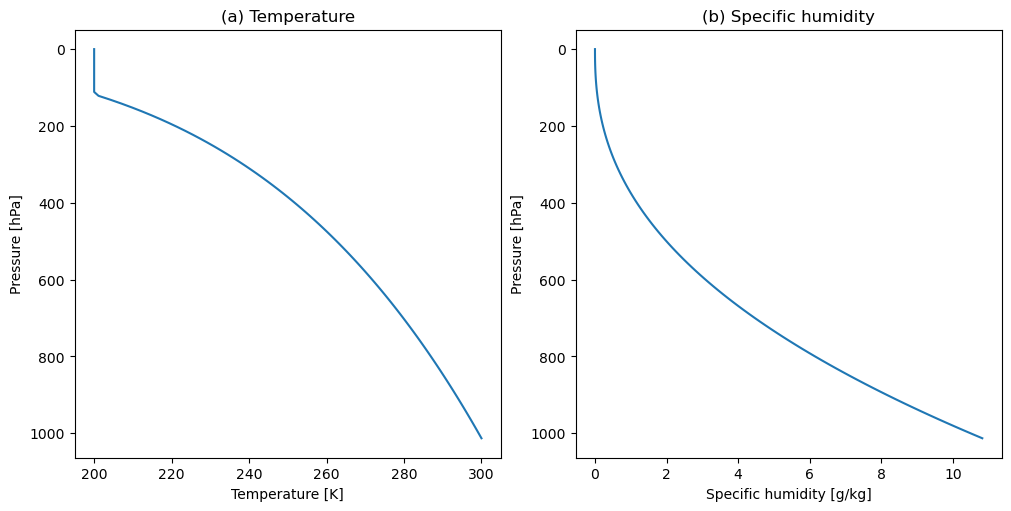

In [46]:
fig, ax = plt.subplots(1,2, squeeze=False, figsize=(10,5), constrained_layout = True)

ax[0,0].plot(T_half, p_half/100)
ax[0,0].invert_yaxis()
ax[0,0].set_title('(a) Temperature')
ax[0,0].set_xlabel('Temperature [K]')
ax[0,0].set_ylabel('Pressure [hPa]')

ax[0,1].plot(q_half * 1000, p_half/100)
ax[0,1].invert_yaxis()
ax[0,1].set_title('(b) Specific humidity')
ax[0,1].set_xlabel('Specific humidity [g/kg]')
ax[0,1].set_ylabel('Pressure [hPa]')
# plt.savefig('idealized_atmosphere.pdf')

## CTS

In [47]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
p_tp = atmosphere.tropopause(Ts = 300)
qco2 = 400e-6

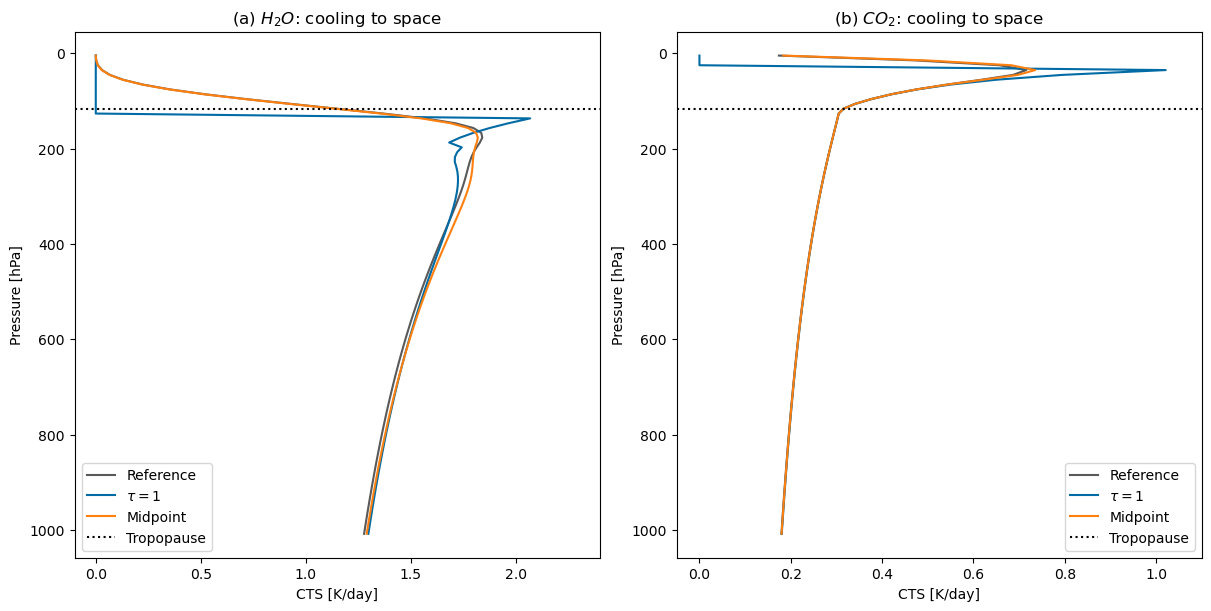

In [48]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

fig, ax = plt.subplots(1,2, figsize=(12,6), constrained_layout = True)

HR_tau1 = cts.cts_tau1_h2o(p,p_half,q, q_half,T,T_half)
HR_transmid = cts.cts_transmid_h2o(p,p_half,q, q_half,T,T_half)
HR_ref = cts.cts_h2o(p_half, q_half, T)

ax[0].plot(HR_ref.sum(axis=0) * 3600 * 24,p/100, c = cb_colors[3], label = 'Reference', linestyle = '-')
ax[0].plot(HR_tau1.sum(axis=0) * 3600 * 24,p/100, c = cb_colors[0], label = r'$\tau = 1$', linestyle = '-')
ax[0].plot(HR_transmid.sum(axis=0) * 3600 * 24,p/100, c = cb_colors[1], label = 'Midpoint', linestyle = '-')

ax[0].hlines(p_tp/100, -0.1, 2.4, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0].set_xlim([-0.1, 2.4])

ax[0].invert_yaxis()

ax[0].set_title(r'(a) $H_2 O$: cooling to space')
ax[0].set_xlabel('CTS [K/day]')
ax[0].set_ylabel('Pressure [hPa]')
ax[0].legend(loc = 'lower left')

qco2 = 400e-6
HR_tau1 = cts.cts_tau1_co2(p,p_half,qco2,T,T_half)
HR_transmid = cts.cts_transmid_co2(p,p_half,qco2,T,T_half)
HR_ref = cts.cts_co2(p_half, qco2, T)

ax[1].plot(HR_ref.sum(axis=0) * 3600 * 24,p/100, c = cb_colors[3], label = 'Reference', linestyle = '-')
ax[1].plot(HR_tau1.sum(axis=0) * 3600 * 24,p/100, c = cb_colors[0], label = r'$\tau = 1$', linestyle = '-')
ax[1].plot(HR_transmid.sum(axis=0) * 3600 * 24,p/100, c = cb_colors[1], label = 'Midpoint', linestyle = '-')

ax[1].hlines(p_tp/100, -0.05, 1.1, color = 'black', linestyle = ':', label = 'Tropopause')
ax[1].set_xlim([-0.05, 1.1])


ax[1].invert_yaxis()

ax[1].set_title(r'(b) $CO_2$: cooling to space')
ax[1].set_xlabel('CTS [K/day]')
ax[1].set_ylabel('Pressure [hPa]')
ax[1].legend(loc = 'lower right')

# plt.savefig('cts_tau1_transmid_h2oco2.pdf')


Text(0, 0.5, 'hPa')

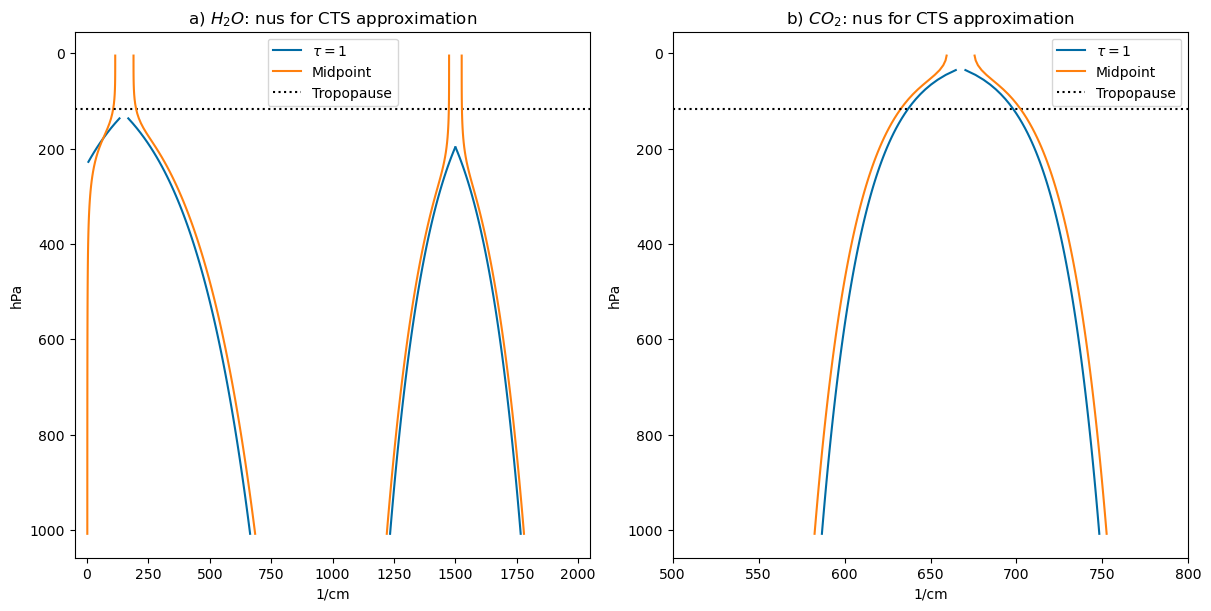

In [49]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

fig, ax = plt.subplots(1,2, figsize=(12,6), constrained_layout = True)


pq = optical.total_pq(p,q)
tau_rot_left_min = pq * optical.k_h2o(nu_min)
tau_rot_right_min = pq * optical.k_h2o(parameters.nu_mid)
tau_rot_max = pq * parameters.kappa_rot
tau_vr_left_min = pq * optical.k_h2o(parameters.nu_mid)
tau_vr_right_min = pq * optical.k_h2o(nu_max)
tau_vr_max = pq * parameters.kappa_vr
trans_nu = np.zeros((4,p.size))
trans_nu[0] = (np.exp(-tau_rot_left_min) + np.exp(-tau_rot_max))/2
trans_nu[1] = (np.exp(-tau_rot_right_min) + np.exp(-tau_rot_max))/2
trans_nu[2] = (np.exp(-tau_vr_left_min) + np.exp(-tau_vr_max))/2
trans_nu[3] = (np.exp(-tau_vr_right_min) + np.exp(-tau_vr_max))/2
nus_tau1_h2o = optical.tau_inverse_h2o(pq, 1)
nus_transmid_h2o = optical.trans_inverse_h2o(pq, trans_nu)
mask1_h2o = (nus_tau1_h2o[0] != -1)
mask2_h2o = (nus_tau1_h2o[1] != -1)
mask3_h2o = (nus_tau1_h2o[2] != -1)
mask4_h2o = (nus_tau1_h2o[3] != -1)

pq = optical.total_pq(p,qco2 + np.zeros_like(p))
tau_co2_left_min = pq * optical.k_co2(nu_min)
tau_co2_right_min = pq * optical.k_co2(nu_max)
tau_co2_max = pq * parameters.kappa_co2
trans_nu = np.zeros((2,p.size))
trans_nu[0] = (np.exp(-tau_co2_left_min) + np.exp(-tau_co2_max))/2
trans_nu[1] = (np.exp(-tau_co2_right_min) + np.exp(-tau_co2_max))/2
nus_tau1_co2 = optical.tau_inverse_co2(pq, 1)
nus_transmid_co2 = optical.trans_inverse_co2(pq, trans_nu)
mask1_co2 = (nus_tau1_co2[0] != -1)
mask2_co2 = (nus_tau1_co2[1] != -1)



ax[0].plot(nus_tau1_h2o[0][mask1_h2o]/100,p[mask1_h2o]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nus_transmid_h2o[0]/100,p/100, c=cb_colors[1], label='Midpoint',linestyle = "-")
ax[0].hlines(p_tp/100, -50,2050, color = 'black', linestyle = ':', label = 'Tropopause')

ax[0].legend()
ax[0].set_xlim(-50,2050)

ax[0].plot(nus_tau1_h2o[1][mask2_h2o]/100,p[mask2_h2o]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nus_tau1_h2o[2][mask3_h2o]/100,p[mask3_h2o]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nus_tau1_h2o[3][mask4_h2o]/100,p[mask4_h2o]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")

ax[0].plot(nus_transmid_h2o[1]/100,p/100, c=cb_colors[1], label='Midpoint',linestyle = "-")
ax[0].plot(nus_transmid_h2o[2]/100,p/100, c=cb_colors[1], label='Midpoint',linestyle = "-")
ax[0].plot(nus_transmid_h2o[3]/100,p/100, c=cb_colors[1], label='Midpoint',linestyle = "-")

ax[0].invert_yaxis()

ax[0].set_title(r'a) $H_2 O$: nus for CTS approximation')
ax[0].set_xlabel('1/cm')
ax[0].set_ylabel('hPa')


ax[1].plot(nus_tau1_co2[0][mask1_co2]/100,p[mask1_co2]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(nus_transmid_co2[0]/100,p/100, c=cb_colors[1], label='Midpoint',linestyle = "-")
ax[1].hlines(p_tp/100, 500,800, color = 'black', linestyle = ':', label = 'Tropopause')

ax[1].legend()
ax[1].set_xlim(500,800)

ax[1].plot(nus_tau1_co2[1][mask2_co2]/100,p[mask2_co2]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(nus_transmid_co2[1]/100,p/100, c=cb_colors[1], label='Midpoint',linestyle = "-")

ax[1].invert_yaxis()

ax[1].set_title(r'b) $CO_2$: nus for CTS approximation')
ax[1].set_xlabel('1/cm')
ax[1].set_ylabel('hPa')

# plt.savefig('nus_tau1_transmid_cts_h2oco2.pdf')

/home/gbertoli/Documents/python_projects/rad_lines/rad_idealized/src/optical.py:90: RuntimeWarning: divide by zero encountered in log
  nu1 = - parameters.l_rot * np.log(pq * parameters.kappa_rot) + nu_rot + parameters.l_rot * np.log(np.abs(np.log(trans[0])))


Text(0, 0.5, 'Average of CTS over pressure [K/day]')

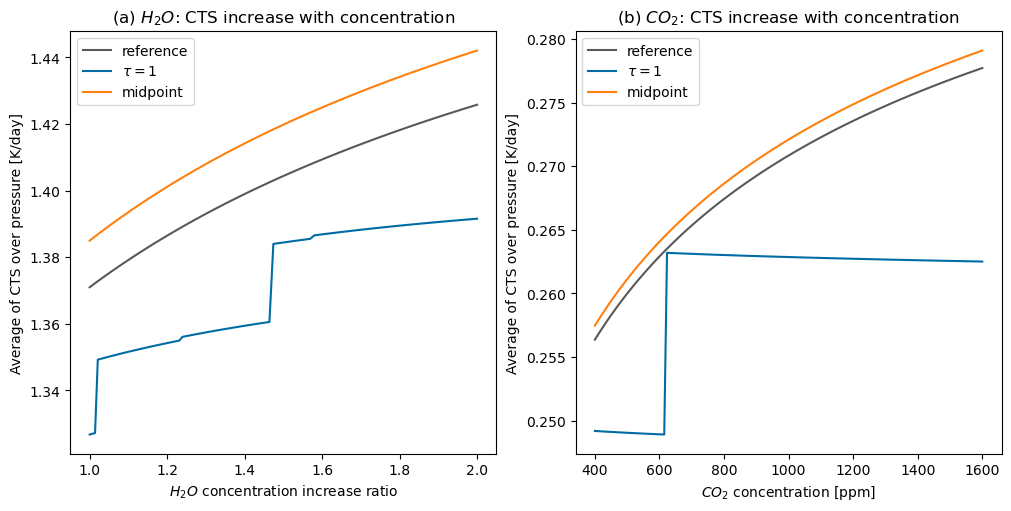

In [50]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

mean_HR_nu_h2o = np.zeros(101)
mean_HR_nu_1_h2o = np.zeros(101)
mean_HR_nu_transavg_h2o = np.zeros(101)
ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
delta_p = p[1:] - p[:-1]
qco2 = 400e-6
for n in range(101):
    q_half2 = ratio_increase[n] * q_half
    q_2 = ratio_increase[n] * q
    
    HR_nu= cts.cts_h2o(p_half, q_half2, T)
    HR_nu_1= cts.cts_tau1_h2o(p,p_half,q_2, q_half2,T,T_half)
    HR_nu_transavg=  cts.cts_transmid_h2o(p,p_half,q_2, q_half2,T,T_half)
    
    mean_HR_nu_h2o[n] = np.sum((HR_nu.sum(axis=0)[1:] + HR_nu.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_1_h2o[n] = np.sum((HR_nu_1.sum(axis=0)[1:] + HR_nu_1.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_transavg_h2o[n] = np.sum((HR_nu_transavg.sum(axis=0)[1:] + HR_nu_transavg.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24


mean_HR_nu_co2 = np.zeros(101)
mean_HR_nu_1_co2 = np.zeros(101)
mean_HR_nu_transavg_co2 = np.zeros(101)
ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
delta_p = p[1:] - p[:-1]
q_co2 = np.array([400e-6 * 2 **(n/50) for n in range(101)])
for n in range(101):
    qco2 = q_co2[n]
    
    HR_nu= cts.cts_co2(p_half, qco2, T)
    HR_nu_1= cts.cts_tau1_co2(p,p_half,qco2,T,T_half)
    HR_nu_transavg =  cts.cts_transmid_co2(p,p_half,qco2,T,T_half)
    
    mean_HR_nu_co2[n] = np.sum((HR_nu.sum(axis=0)[1:] + HR_nu.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_1_co2[n] = np.sum((HR_nu_1.sum(axis=0)[1:] + HR_nu_1.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_transavg_co2[n] = np.sum((HR_nu_transavg.sum(axis=0)[1:] + HR_nu_transavg.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24



fig, ax = plt.subplots(1,2, figsize=(10,5), constrained_layout = True)

ax[0].plot(ratio_increase, mean_HR_nu_h2o, c=cb_colors[3], label='reference',linestyle = "-")
ax[0].plot(ratio_increase, mean_HR_nu_1_h2o, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(ratio_increase, mean_HR_nu_transavg_h2o, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[0].legend()

ax[0].set_title(r"(a) $H_2 O$: CTS increase with concentration")
ax[0].set_xlabel(r"$H_2 O$ concentration increase ratio")
ax[0].set_ylabel(r'Average of CTS over pressure [K/day]')

ax[1].plot(q_co2 * 1e6, mean_HR_nu_co2, c=cb_colors[3], label='reference',linestyle = "-")
ax[1].plot(q_co2 * 1e6, mean_HR_nu_1_co2, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(q_co2 * 1e6, mean_HR_nu_transavg_co2, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[1].legend()

ax[1].set_title(r"(b) $CO_2$: CTS increase with concentration")
ax[1].set_xlabel(r"$CO_2$ concentration [ppm]")
ax[1].set_ylabel('Average of CTS over pressure [K/day]')

# plt.savefig('cts_sensitivity_h2oco2.pdf')

## OLR

In [51]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

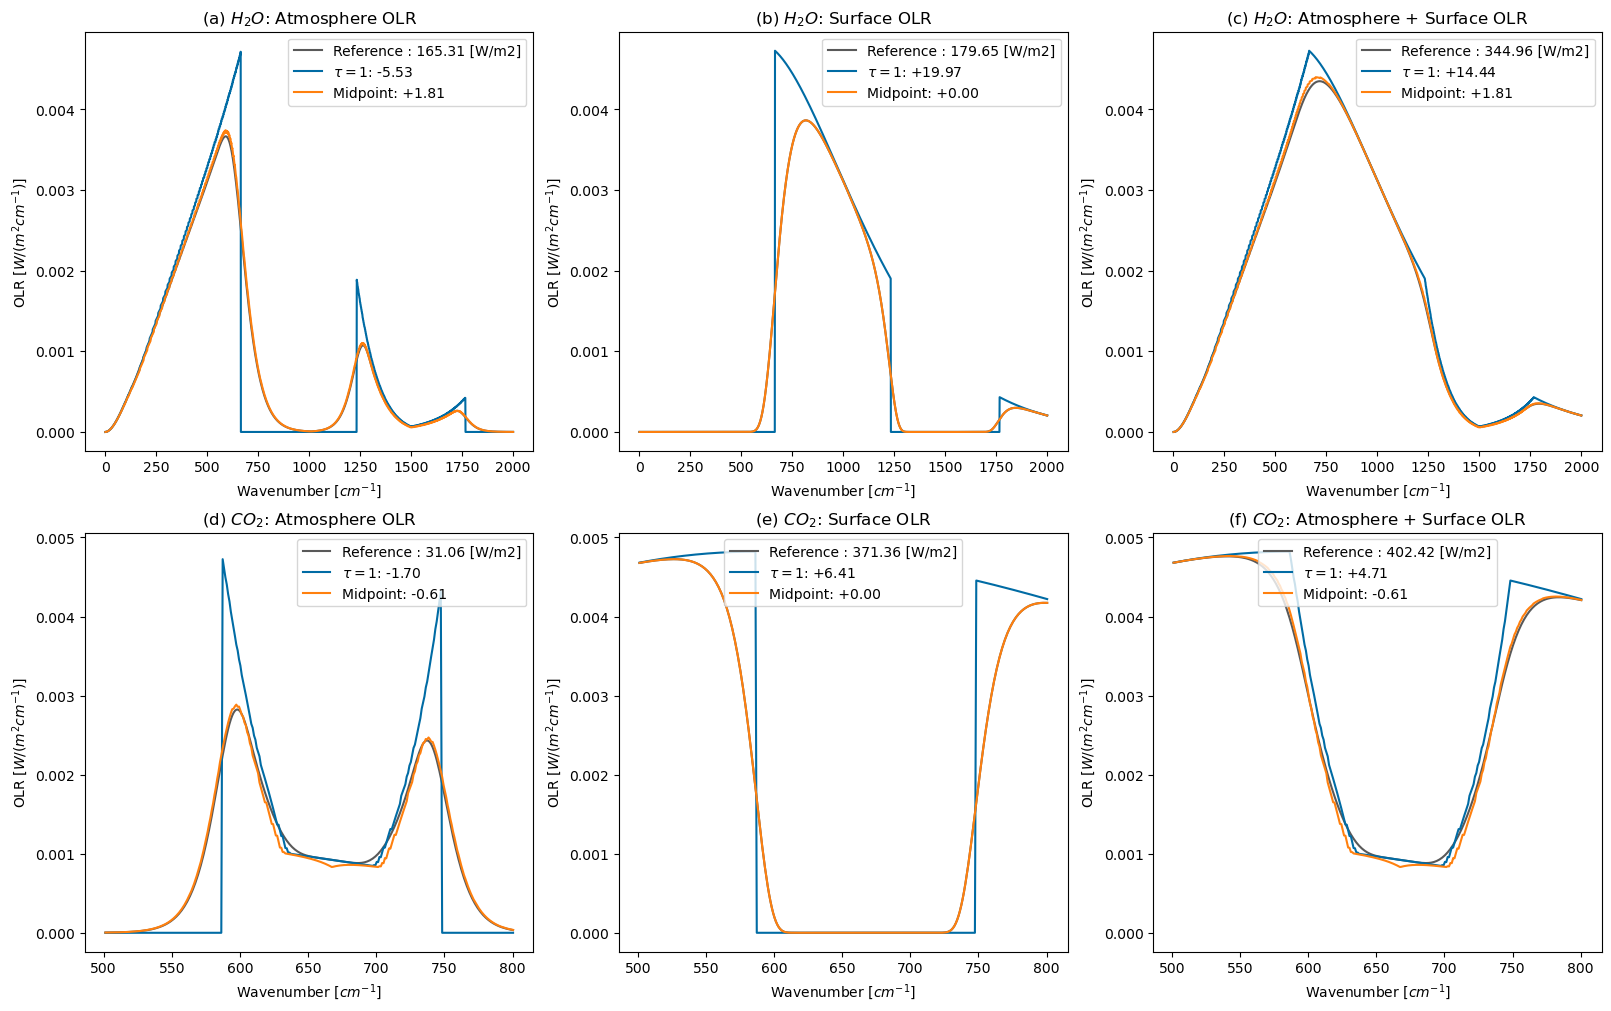

In [52]:
fig, ax = plt.subplots(2, 3, squeeze=False, figsize=(16,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

pq = optical.local_pq(p_half, q_half)

nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))

delta_nu = nu[1] - nu[0]


olr_atm, olr_surf = olr.olr_h2o(p_half, q_half, T, T_half[-1])
olr_atm_tau1, olr_surf_tau1 = olr.olr_tau1_h2o(p_half, q_half, T, T_half[-1])
olr_atm_midpoint, olr_surf_midpoint =  olr.olr_transmid_h2o(p_half, q_half, T, T_half[-1])

integrated_olr_atm = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu)
integrated_olr_surf = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu)

integrated_olr_atm_tau1 = np.sum((olr_atm_tau1[1:] + olr_atm_tau1[:-1])/2 * delta_nu)
integrated_olr_surf_tau1 = np.sum((olr_surf_tau1[1:] + olr_surf_tau1[:-1])/2 * delta_nu)

integrated_olr_atm_midpoint = np.sum((olr_atm_midpoint[1:] + olr_atm_midpoint[:-1])/2 * delta_nu)
integrated_olr_surf_midpoint = np.sum((olr_surf_midpoint[1:] + olr_surf_midpoint[:-1])/2 * delta_nu)

linestyle_ref = "-"
linestyle_transavg = "-"
linestyle_tau1 = "-"

ax[0,0].plot(nu/100, olr_atm , color = cb_colors[3], label = 'Reference', linestyle = linestyle_ref)
ax[0,0].plot(nu/100, olr_atm_tau1, color = cb_colors[0], label = 'tau = 1', linestyle = linestyle_tau1)
ax[0,0].plot(nu/100, olr_atm_midpoint, color = cb_colors[1], label = '(trans_top + trans_surf)/2', linestyle = linestyle_transavg)


ax[0,0].legend([f"Reference : {integrated_olr_atm:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_olr_atm_tau1) - (integrated_olr_atm):+.2f}", 
                rf"Midpoint: {(integrated_olr_atm_midpoint) - (integrated_olr_atm):+.2f}"
               ],loc='upper right')

ax[0,1].plot(nu/100, olr_surf , color = cb_colors[3], label = 'Reference OLR', linestyle = linestyle_ref)
ax[0,1].plot(nu/100, olr_surf_tau1, color = cb_colors[0], label = 'tau = 1', linestyle = linestyle_tau1)
ax[0,1].plot(nu/100, olr_surf_midpoint, color = cb_colors[1], label = 'Average transmissivity', linestyle = linestyle_transavg)


ax[0,1].legend([f"Reference : {integrated_olr_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_olr_surf_tau1) - (integrated_olr_surf):+.2f}", 
                rf"Midpoint: {(integrated_olr_surf_midpoint) - (integrated_olr_surf):+.2f}"
               ],loc='upper right')

ax[0,2].plot(nu/100, olr_atm + olr_surf , color = cb_colors[3], label = 'Reference OLR', linestyle = linestyle_ref)
ax[0,2].plot(nu/100, olr_atm_tau1 + olr_surf_tau1, color = cb_colors[0], label = 'tau = 1', linestyle = linestyle_tau1)
ax[0,2].plot(nu/100, olr_atm_midpoint + olr_surf_midpoint, color = cb_colors[1], label = 'Average transmissivity', linestyle = linestyle_transavg)



y_lim_max = np.max((olr_atm + olr_surf, olr_atm_midpoint + olr_surf_midpoint, olr_atm_tau1 + olr_surf_tau1))
y_lim_min = np.min((olr_atm + olr_surf, olr_atm_midpoint + olr_surf_midpoint, olr_atm_tau1 + olr_surf_tau1))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05


ax[0,2].legend([f"Reference : {integrated_olr_atm+integrated_olr_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_olr_atm_tau1+integrated_olr_surf_tau1) - (integrated_olr_atm+integrated_olr_surf):+.2f}", 
                rf"Midpoint: {(integrated_olr_atm_midpoint + integrated_olr_surf_midpoint) - (integrated_olr_atm+integrated_olr_surf):+.2f}"
               ],loc='upper right')

ax[0,0].set_title(r"(a) $H_2 O$: Atmosphere OLR")
ax[0,1].set_title(r"(b) $H_2 O$: Surface OLR")
ax[0,2].set_title(r"(c) $H_2 O$: Atmosphere + Surface OLR")

for i in range(3):
    ax[0,i].set_ylabel(r'OLR $[W/(m^2 cm^{-1})]$')
    ax[0,i].set_xlabel(r'Wavenumber [$cm^{-1}$]')
    ax[0,i].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

nu_a = 500
nu_b = 800

nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
delta_nu = nu[1] - nu[0]
olr_atm, olr_surf = olr.olr_co2(p_half, qco2, T, T_half[-1])
olr_atm_tau1, olr_surf_tau1 = olr.olr_tau1_co2(p_half, qco2, T, T_half[-1])
olr_atm_midpoint, olr_surf_midpoint =  olr.olr_transmid_co2(p_half, qco2, T, T_half[-1])

integrated_olr_atm = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu)
integrated_olr_surf = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu)

integrated_olr_atm_tau1 = np.sum((olr_atm_tau1[1:] + olr_atm_tau1[:-1])/2 * delta_nu)
integrated_olr_surf_tau1 = np.sum((olr_surf_tau1[1:] + olr_surf_tau1[:-1])/2 * delta_nu)

integrated_olr_atm_midpoint = np.sum((olr_atm_midpoint[1:] + olr_atm_midpoint[:-1])/2 * delta_nu)
integrated_olr_surf_midpoint = np.sum((olr_surf_midpoint[1:] + olr_surf_midpoint[:-1])/2 * delta_nu)


ax[1,0].plot(nu[nu_a:nu_b]/100, olr_atm[nu_a:nu_b] , color = cb_colors[3], label = 'Reference OLR')
ax[1,0].plot(nu[nu_a:nu_b]/100, olr_atm_tau1[nu_a:nu_b], color = cb_colors[0], label = 'tau = 1')
ax[1,0].plot(nu[nu_a:nu_b]/100, olr_atm_midpoint[nu_a:nu_b], color = cb_colors[1], label = 'Average transmissivity')


ax[1,0].legend([f"Reference : {integrated_olr_atm:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_olr_atm_tau1) - (integrated_olr_atm):+.2f}", 
                rf"Midpoint: {(integrated_olr_atm_midpoint) - (integrated_olr_atm):+.2f}"
               ],loc='upper right')

ax[1,1].plot(nu[nu_a:nu_b]/100, olr_surf[nu_a:nu_b] , color = cb_colors[3], label = 'Reference OLR')
ax[1,1].plot(nu[nu_a:nu_b]/100, olr_surf_tau1[nu_a:nu_b], color = cb_colors[0], label = 'tau = 1')
ax[1,1].plot(nu[nu_a:nu_b]/100, olr_surf_midpoint[nu_a:nu_b], color = cb_colors[1], label = 'Average transmissivity')

ax[1,1].legend([f"Reference : {integrated_olr_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_olr_surf_tau1) - (integrated_olr_surf):+.2f}", 
                rf"Midpoint: {(integrated_olr_surf_midpoint) - (integrated_olr_surf):+.2f}"
               ],loc='upper center')

ax[1,2].plot(nu[nu_a:nu_b]/100, olr_atm[nu_a:nu_b] + olr_surf[nu_a:nu_b] , color = cb_colors[3], label = 'Reference OLR')
ax[1,2].plot(nu[nu_a:nu_b]/100, olr_atm_tau1[nu_a:nu_b] + olr_surf_tau1[nu_a:nu_b], color = cb_colors[0], label = 'tau = 1')
ax[1,2].plot(nu[nu_a:nu_b]/100, olr_atm_midpoint[nu_a:nu_b] + olr_surf_midpoint[nu_a:nu_b], color = cb_colors[1], label = 'Average transmissivity')


ax[1,2].legend([f"Reference : {integrated_olr_atm+integrated_olr_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_olr_atm_tau1+integrated_olr_surf_tau1) - (integrated_olr_atm+integrated_olr_surf):+.2f}", 
                rf"Midpoint: {(integrated_olr_atm_midpoint + integrated_olr_surf_midpoint) - (integrated_olr_atm+integrated_olr_surf):+.2f}"
               ],loc='upper center')

y_lim_max = np.max((olr_atm + olr_surf, olr_atm_midpoint + olr_surf_midpoint, olr_atm_tau1 + olr_surf_tau1))
y_lim_min = np.min((olr_atm + olr_surf, olr_atm_midpoint + olr_surf_midpoint, olr_atm_tau1 + olr_surf_tau1))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05


ax[1,0].set_title(r"(d) $CO_2$: Atmosphere OLR")
ax[1,1].set_title(r"(e) $CO_2$: Surface OLR")
ax[1,2].set_title(r"(f) $CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[1,i].set_ylabel(r'OLR $[W/(m^2 cm^{-1})]$')
    ax[1,i].set_xlabel(r'Wavenumber [$cm^{-1}$]')
    ax[1,i].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

# plt.savefig('OLR_h2oco2.pdf')

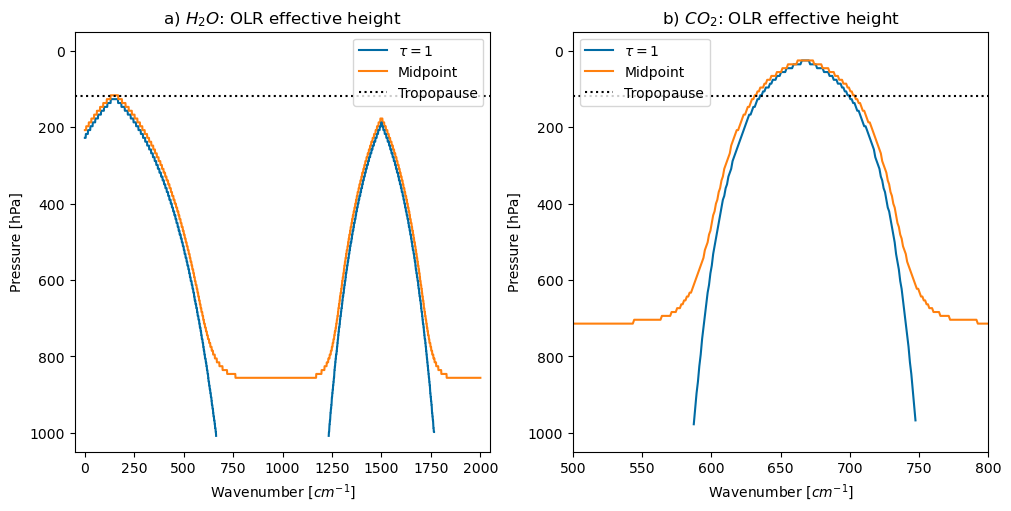

In [53]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

pq = optical.local_pq(p_half, q_half)
nu =  np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
tau_local = pq.reshape(-1,1) * optical.k_h2o(nu).reshape(1,-1)
tau = np.cumsum(tau_local, axis = 0)
trans = np.exp(-tau)
trans_max = trans[0,:]
trans_min = trans[-1,:]
i_tau_midoint_h2o = np.argmin(np.abs(trans - (trans_max + trans_min)/2), axis = 0)
i_tau1_h2o = np.argmin(np.abs(tau - 1), axis = 0)
mask_1_h2o_left = ~((tau[-1] < 1) | (nu >= 100000))
mask_1_h2o_right = ~((tau[-1] < 1) | (nu < 100000))



pq = optical.local_pq(p_half, qco2 + np.zeros_like(q_half))
nu =  np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
tau_local = pq.reshape(-1,1) * optical.k_co2(nu).reshape(1,-1)
tau = np.cumsum(tau_local, axis = 0)
trans = np.exp(-tau)
trans_max = trans[0,:]
trans_min = trans[-1,:]
i_tau_midoint_co2 = np.argmin(np.abs(trans - (trans_max + trans_min)/2), axis = 0)
i_tau1_co2 = np.argmin(np.abs(tau - 1), axis = 0)
mask_1_co2 = ~(tau[-1] < 1)


fig, ax = plt.subplots(1,2, figsize=(10,5), constrained_layout = True)


ax[0].plot(nu[mask_1_h2o_left]/100,p[i_tau1_h2o][mask_1_h2o_left]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nu/100,p[i_tau_midoint_h2o]/100, c=cb_colors[1], label="Midpoint", linestyle = "-")
ax[0].hlines(p_tp/100, -50,2050, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0].legend()
ax[0].plot(nu[mask_1_h2o_right]/100,p[i_tau1_h2o][mask_1_h2o_right]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")


ax[0].set_xlim(-50,2050)
ax[0].set_ylim(-50,1050)

ax[0].invert_yaxis()

ax[0].set_title(r'a) $H_2 O$: OLR effective height')
ax[0].set_xlabel(r'Wavenumber $[cm^{-1}]$')
ax[0].set_ylabel('Pressure [hPa]')


nu_a = 500
nu_b = 800

ax[1].plot(nu[mask_1_co2]/100,p[i_tau1_co2][mask_1_co2]/100, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(nu[nu_a:nu_b]/100,p[i_tau_midoint_co2][nu_a:nu_b]/100, c=cb_colors[1], label="Midpoint", linestyle = "-")

ax[1].hlines(p_tp/100, 500,800, color = 'black', linestyle = ':', label = 'Tropopause')

ax[1].legend()
ax[1].set_xlim(500,800)
ax[1].set_ylim(-50,1050)

ax[1].invert_yaxis()

ax[1].set_title(r'b) $CO_2$: OLR effective height')
ax[1].set_xlabel(r'Wavenumber $[cm^{-1}]$')
ax[1].set_ylabel('Pressure [hPa]')
ax[1].legend()
# plt.savefig('nus_tau1_transmid_h2oco2.pdf')

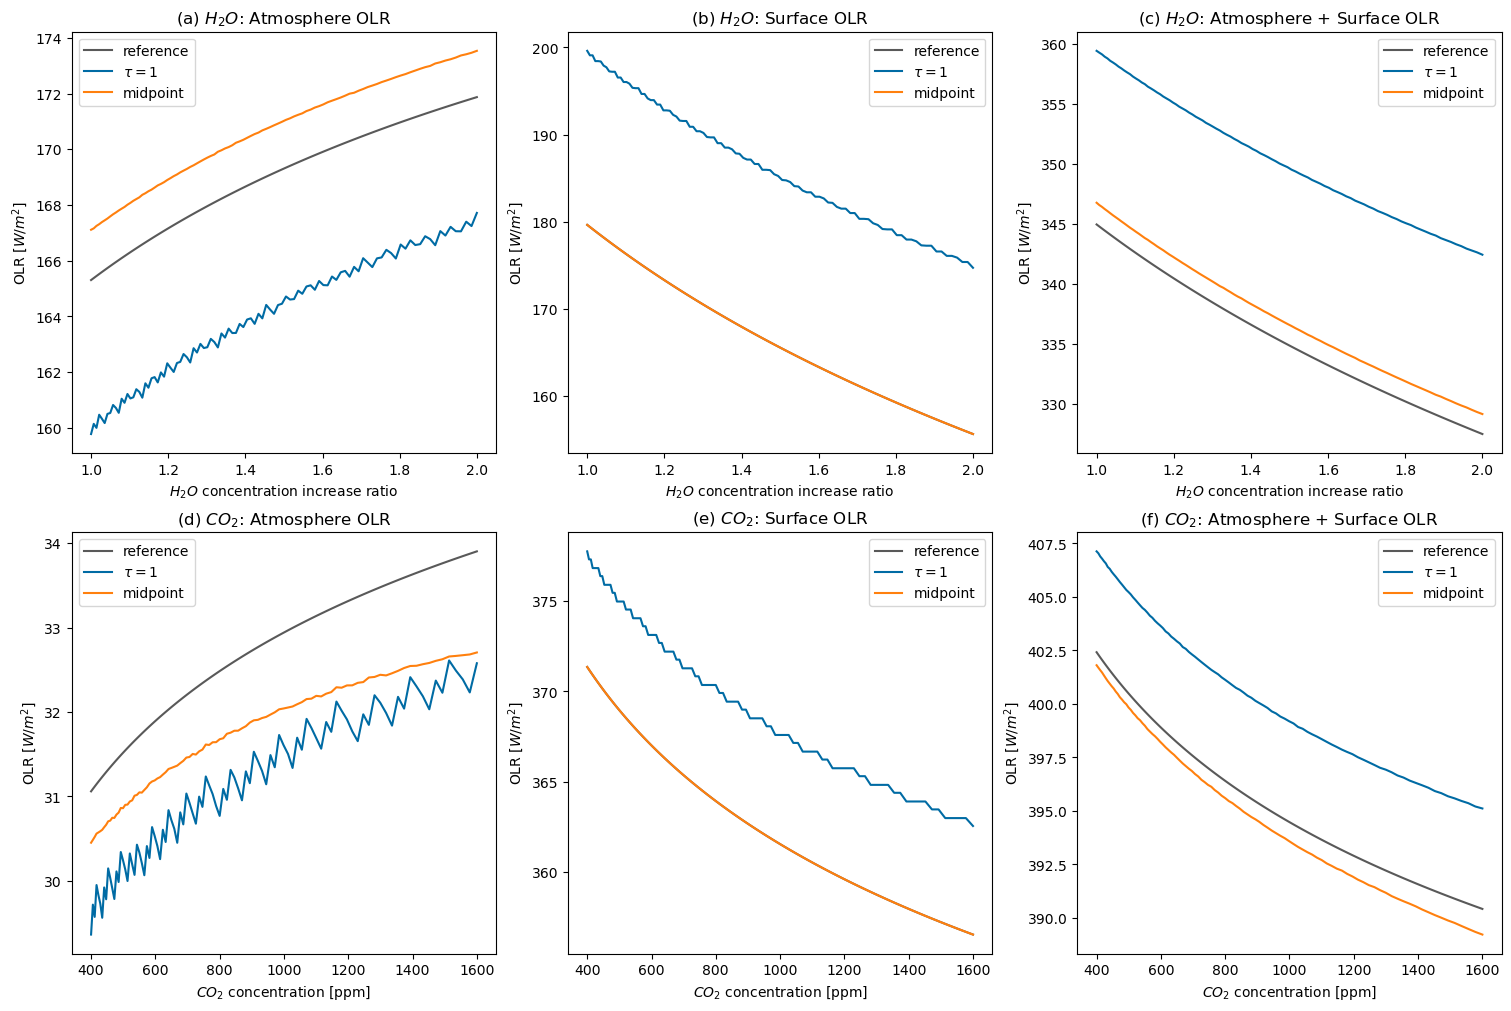

In [54]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
delta_nu = nu[1] - nu[0]

olr_atm_h2o = np.zeros(101)
olr_surf_h2o = np.zeros(101)
olr_atm_tau1_h2o = np.zeros(101)
olr_surf_tau1_h2o = np.zeros(101)
olr_atm_midpoint_h2o = np.zeros(101)
olr_surf_midpoint_h2o = np.zeros(101)

ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
qco2 = 400e-6
for n in range(101):
    q_half2 = ratio_increase[n] * q_half
    olr_atm, olr_surf = olr.olr_h2o(p_half, q_half2, T, T_half[-1])
    olr_atm_tau1, olr_surf_tau1 = olr.olr_tau1_h2o(p_half, q_half2, T, T_half[-1])
    olr_atm_midpoint, olr_surf_midpoint =  olr.olr_transmid_h2o(p_half, q_half2, T, T_half[-1])
    
    
    olr_atm_h2o[n] = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu)
    olr_surf_h2o[n] = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu)
    
    olr_atm_tau1_h2o[n] = np.sum((olr_atm_tau1[1:] + olr_atm_tau1[:-1])/2 * delta_nu)
    olr_surf_tau1_h2o[n] = np.sum((olr_surf_tau1[1:] + olr_surf_tau1[:-1])/2 * delta_nu)
    
    olr_atm_midpoint_h2o[n] = np.sum((olr_atm_midpoint[1:] + olr_atm_midpoint[:-1])/2 * delta_nu)
    olr_surf_midpoint_h2o[n] = np.sum((olr_surf_midpoint[1:] + olr_surf_midpoint[:-1])/2 * delta_nu)

olr_atm_co2 = np.zeros(101)
olr_surf_co2 = np.zeros(101)
olr_atm_tau1_co2 = np.zeros(101)
olr_surf_tau1_co2 = np.zeros(101)
olr_atm_midpoint_co2 = np.zeros(101)
olr_surf_midpoint_co2 = np.zeros(101)
q_co2 = np.array([400e-6 * 2 **(n/50) for n in range(101)])
for n in range(101):
    qco2_temp = q_co2[n]
    olr_atm, olr_surf = olr.olr_co2(p_half, qco2_temp, T, T_half[-1])
    olr_atm_tau1, olr_surf_tau1 = olr.olr_tau1_co2(p_half, qco2_temp, T, T_half[-1])
    olr_atm_midpoint, olr_surf_midpoint =  olr.olr_transmid_co2(p_half, qco2_temp, T, T_half[-1])

    
    olr_atm_co2[n] = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu)
    olr_surf_co2[n] = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu)
    
    olr_atm_tau1_co2[n] = np.sum((olr_atm_tau1[1:] + olr_atm_tau1[:-1])/2 * delta_nu)
    olr_surf_tau1_co2[n] = np.sum((olr_surf_tau1[1:] + olr_surf_tau1[:-1])/2 * delta_nu)
    
    olr_atm_midpoint_co2[n] = np.sum((olr_atm_midpoint[1:] + olr_atm_midpoint[:-1])/2 * delta_nu)
    olr_surf_midpoint_co2[n] = np.sum((olr_surf_midpoint[1:] + olr_surf_midpoint[:-1])/2 * delta_nu)

fig, ax = plt.subplots(2,3, figsize=(15,10), constrained_layout = True)

ax[0,0].plot(ratio_increase, olr_atm_h2o, c=cb_colors[3], label='reference',linestyle = "-")
ax[0,0].plot(ratio_increase, olr_atm_tau1_h2o, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0,0].plot(ratio_increase, olr_atm_midpoint_h2o, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[0,0].legend()

ax[0,1].plot(ratio_increase, olr_surf_h2o, c=cb_colors[3], label='reference',linestyle = "-")
ax[0,1].plot(ratio_increase, olr_surf_tau1_h2o, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0,1].plot(ratio_increase, olr_surf_midpoint_h2o, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[0,1].legend()

ax[0,2].plot(ratio_increase, olr_atm_h2o + olr_surf_h2o, c=cb_colors[3], label='reference',linestyle = "-")
ax[0,2].plot(ratio_increase, olr_atm_tau1_h2o + olr_surf_tau1_h2o, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0,2].plot(ratio_increase, olr_atm_midpoint_h2o + olr_surf_midpoint_h2o, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[0,2].legend()

ax[0,0].set_title(r"(a) $H_2 O$: Atmosphere OLR")
ax[0,1].set_title(r"(b) $H_2 O$: Surface OLR")
ax[0,2].set_title(r"(c) $H_2 O$: Atmosphere + Surface OLR")

for i in range(3):
    ax[0,i].set_xlabel(r"$H_2 O$ concentration increase ratio")
    ax[0,i].set_ylabel(r'OLR $[W/m^2]$')

ax[1,0].plot(q_co2 * 1e6, olr_atm_co2, c=cb_colors[3], label='reference',linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, olr_atm_tau1_co2, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, olr_atm_midpoint_co2, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[1,0].legend()

ax[1,1].plot(q_co2 * 1e6, olr_surf_co2, c=cb_colors[3], label='reference',linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, olr_surf_tau1_co2, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, olr_surf_midpoint_co2, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[1,1].legend()

ax[1,2].plot(q_co2 * 1e6, olr_atm_co2 + olr_surf_co2, c=cb_colors[3], label='reference',linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, olr_atm_tau1_co2 + olr_surf_tau1_co2, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, olr_atm_midpoint_co2 + olr_surf_midpoint_co2, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[1,2].legend()

ax[1,0].set_title(r"(d) $CO_2$: Atmosphere OLR")
ax[1,1].set_title(r"(e) $CO_2$: Surface OLR")
ax[1,2].set_title(r"(f) $CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[1,i].set_xlabel(r"$CO_2$ concentration [ppm]")
    ax[1,i].set_ylabel(r'OLR $[W/m^2]$')

# plt.savefig('olr_sensitivity_h2oco2.pdf')


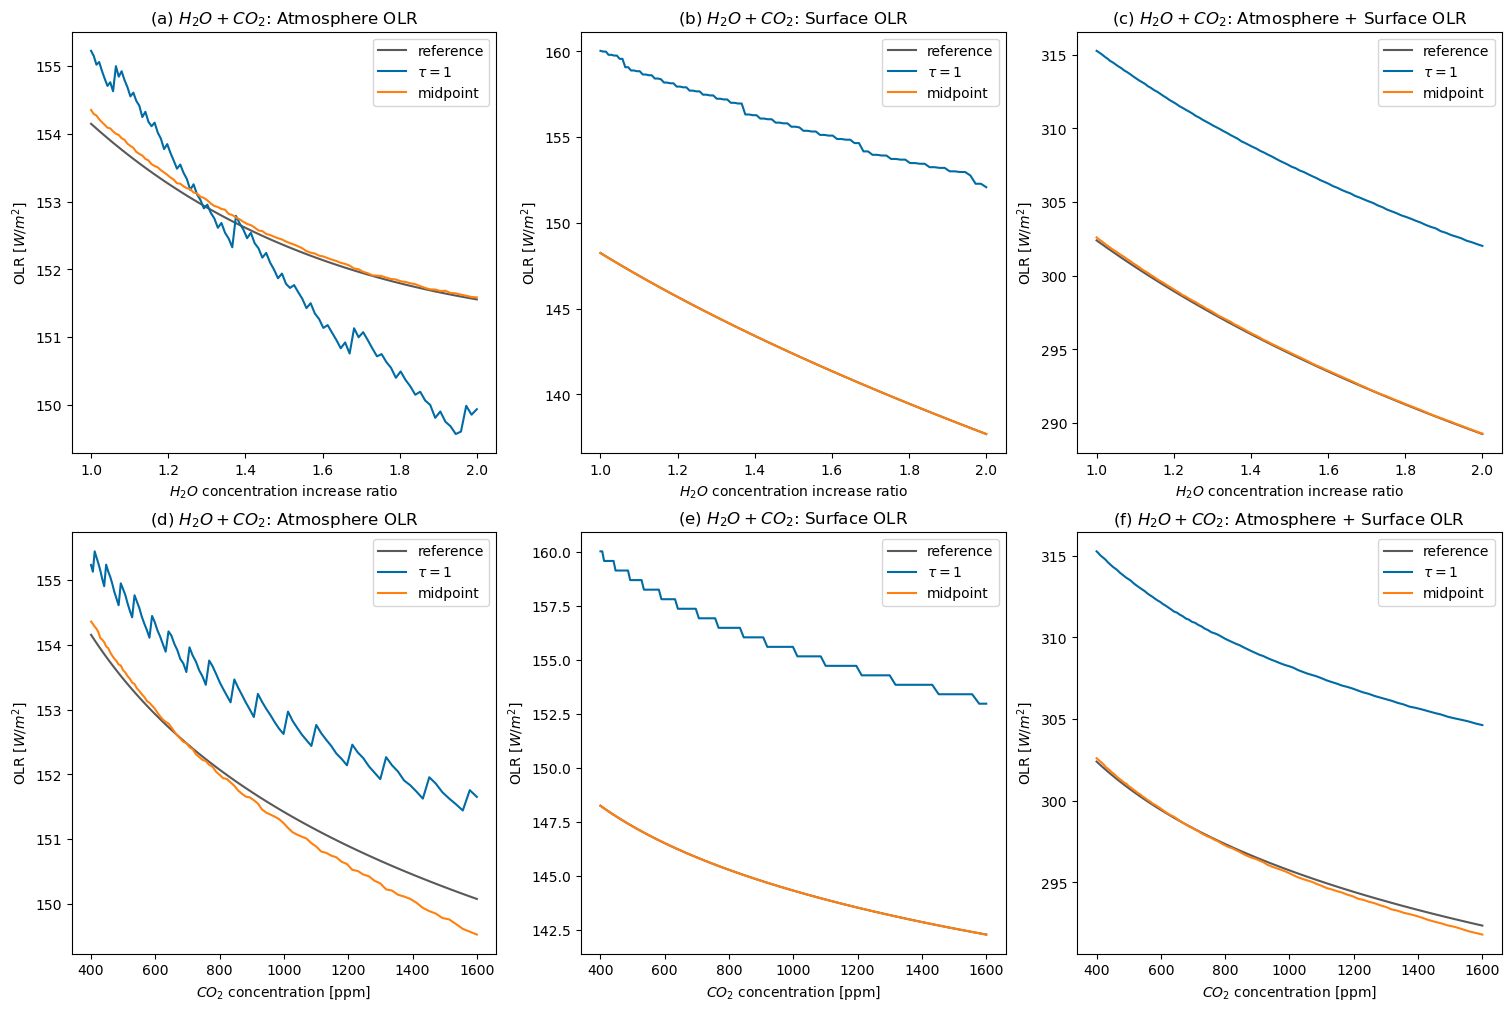

In [55]:
T, T_half, q, q_half, p, p_half = atmosphere.atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
delta_nu = nu[1] - nu[0]


olr_atm_h2oco2_co2up = np.zeros(101)
olr_surf_h2oco2_co2up = np.zeros(101)
olr_atm_tau1_h2oco2_co2up = np.zeros(101)
olr_surf_tau1_h2oco2_co2up = np.zeros(101)
olr_atm_midpoint_h2oco2_co2up = np.zeros(101)
olr_surf_midpoint_h2oco2_co2up = np.zeros(101)
q_co2 = np.array([400e-6 * 2 **(n/50) for n in range(101)])

for n in range(101):
    qco2_temp = q_co2[n]
    olr_atm, olr_surf = olr.olr_h2o_co2(p_half, q_half, qco2_temp, T, T_half[-1])
    olr_atm_tau1, olr_surf_tau1 = olr.olr_tau1_h2o_co2(p_half, q_half,qco2_temp, T,T_half[-1])
    olr_atm_midpoint, olr_surf_midpoint =  olr.olr_transmid_h2o_co2(p_half, q_half,qco2_temp, T,T_half[-1])
    
    olr_atm_h2oco2_co2up[n] = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu)
    olr_surf_h2oco2_co2up[n] = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu)
    
    olr_atm_tau1_h2oco2_co2up[n] = np.sum((olr_atm_tau1[1:] + olr_atm_tau1[:-1])/2 * delta_nu)
    olr_surf_tau1_h2oco2_co2up[n] = np.sum((olr_surf_tau1[1:] + olr_surf_tau1[:-1])/2 * delta_nu)
    
    olr_atm_midpoint_h2oco2_co2up[n] = np.sum((olr_atm_midpoint[1:] + olr_atm_midpoint[:-1])/2 * delta_nu)
    olr_surf_midpoint_h2oco2_co2up[n] = np.sum((olr_surf_midpoint[1:] + olr_surf_midpoint[:-1])/2 * delta_nu)

olr_atm_h2oco2_h2oup = np.zeros(101)
olr_surf_h2oco2_h2oup = np.zeros(101)
olr_atm_tau1_h2oco2_h2oup = np.zeros(101)
olr_surf_tau1_h2oco2_h2oup = np.zeros(101)
olr_atm_midpoint_h2oco2_h2oup = np.zeros(101)
olr_surf_midpoint_h2oco2_h2oup = np.zeros(101)
ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
for n in range(101):
    q_half2 = ratio_increase[n] * q_half
    olr_atm, olr_surf = olr.olr_h2o_co2(p_half, q_half2,qco2, T, T_half[-1])
    olr_atm_tau1, olr_surf_tau1 = olr.olr_tau1_h2o_co2(p_half, q_half2,qco2, T,T_half[-1])
    olr_atm_midpoint, olr_surf_midpoint =  olr.olr_transmid_h2o_co2(p_half, q_half2,qco2, T,T_half[-1])
    
    olr_atm_h2oco2_h2oup[n] = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu)
    olr_surf_h2oco2_h2oup[n] = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu)
    
    olr_atm_tau1_h2oco2_h2oup[n] = np.sum((olr_atm_tau1[1:] + olr_atm_tau1[:-1])/2 * delta_nu)
    olr_surf_tau1_h2oco2_h2oup[n] = np.sum((olr_surf_tau1[1:] + olr_surf_tau1[:-1])/2 * delta_nu)
    
    olr_atm_midpoint_h2oco2_h2oup[n] = np.sum((olr_atm_midpoint[1:] + olr_atm_midpoint[:-1])/2 * delta_nu)
    olr_surf_midpoint_h2oco2_h2oup[n] = np.sum((olr_surf_midpoint[1:] + olr_surf_midpoint[:-1])/2 * delta_nu)

fig, ax = plt.subplots(2,3, figsize=(15,10), constrained_layout = True)

ax[0,0].plot(ratio_increase, olr_atm_h2oco2_h2oup, c=cb_colors[3], label='reference',linestyle = "-")
ax[0,0].plot(ratio_increase, olr_atm_tau1_h2oco2_h2oup, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0,0].plot(ratio_increase, olr_atm_midpoint_h2oco2_h2oup, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[0,0].legend()

ax[0,1].plot(ratio_increase, olr_surf_h2oco2_h2oup, c=cb_colors[3], label='reference',linestyle = "-")
ax[0,1].plot(ratio_increase, olr_surf_tau1_h2oco2_h2oup, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0,1].plot(ratio_increase, olr_surf_midpoint_h2oco2_h2oup, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[0,1].legend()

ax[0,2].plot(ratio_increase, olr_atm_h2oco2_h2oup + olr_surf_h2oco2_h2oup, c=cb_colors[3], label='reference',linestyle = "-")
ax[0,2].plot(ratio_increase, olr_atm_tau1_h2oco2_h2oup + olr_surf_tau1_h2oco2_h2oup, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[0,2].plot(ratio_increase, olr_atm_midpoint_h2oco2_h2oup + olr_surf_midpoint_h2oco2_h2oup, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[0,2].legend()

ax[0,0].set_title(r"(a) $H_2 O + CO_2$: Atmosphere OLR")
ax[0,1].set_title(r"(b) $H_2 O + CO_2$: Surface OLR")
ax[0,2].set_title(r"(c) $H_2 O + CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[0,i].set_xlabel(r"$H_2 O$ concentration increase ratio")
    ax[0,i].set_ylabel(r'OLR $[W/m^2]$')


ax[1,0].plot(q_co2 * 1e6, olr_atm_h2oco2_co2up, c=cb_colors[3], label='reference',linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, olr_atm_tau1_h2oco2_co2up, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, olr_atm_midpoint_h2oco2_co2up, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[1,0].legend()

ax[1,1].plot(q_co2 * 1e6, olr_surf_h2oco2_co2up, c=cb_colors[3], label='reference',linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, olr_surf_tau1_h2oco2_co2up, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, olr_surf_midpoint_h2oco2_co2up, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[1,1].legend()

ax[1,2].plot(q_co2 * 1e6, olr_atm_h2oco2_co2up + olr_surf_h2oco2_co2up, c=cb_colors[3], label='reference',linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, olr_atm_tau1_h2oco2_co2up + olr_surf_tau1_h2oco2_co2up, c=cb_colors[0], label=r'$\tau = 1$', linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, olr_atm_midpoint_h2oco2_co2up + olr_surf_midpoint_h2oco2_co2up, c=cb_colors[1], label='midpoint', linestyle = "-")
ax[1,2].legend()

ax[1,0].set_title(r"(d) $H_2O + CO_2$: Atmosphere OLR")
ax[1,1].set_title(r"(e) $H_2O + CO_2$: Surface OLR")
ax[1,2].set_title(r"(f) $H_2O + CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[1,i].set_xlabel(r"$CO_2$ concentration [ppm]")
    ax[1,i].set_ylabel(r'OLR $[W/m^2]$')

# plt.savefig('olr_sensitivity_h2o_plus_co2.pdf')
